
# Semantic Memory - Exploratory Data Analysis

**Paper context:** *The Role of System 1 and System 2 Semantic Memory Structure in Human and LLM Biases* (Abramski, Rossetti & Stella, 2026)

## 1. Introduction

This notebook explores the datasets used in the paper, focusing on semantic associations produced by humans and large language models (LLMs). The main goal is to understand how the data is structured, identify common patterns, and compare human and LLM-generated word associations.

We will use descriptive statistics and visualizations to explore the data, rather than reproduce the full experiments from the paper.



### 1.1 Environment Setup

We will use Python and Pandas to load, inspect, and analyze the datasets. NumPy will be used for numerical operations, while Plotly will help us create interactive visualizations.


In [125]:

import pandas as pd
import numpy as np
import plotly.express as px

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)



## 2. Dataset Description

This analysis focuses on two sources of semantic word associations:

- **SWOW (Small World of Words):** A dataset containing word associations collected from human participants. Given a cue word, participants provide words that come to mind.

- **LWOW (Large World of Words):** A dataset of word associations generated by large language models. It allows us to explore how LLM-generated associations compare with human responses.

We will mainly focus on these two datasets to investigate differences and similarities in word association patterns.

The exact dataset structure, available columns, and number of observations will be examined after loading the data.



## 3. Data Loading & Initial Inspection

In this section, we load the SWOW and LWOW datasets and examine their structure.

We will check the available columns, data types, number of observations, and missing values before starting the analysis.


In [126]:
from pathlib import Path

DATA_DIR = Path("data")

print("Available datasets:")

for path in sorted(DATA_DIR.rglob("*.csv")):
    print(path)

Available datasets:
data/lwow/FA_Llama3.csv
data/lwow/FA_Mistral.csv
data/swow/SWOW-EN.R100.20180827.csv



### 3.1 Loading the SWOW Dataset

We will start by loading the SWOW dataset, which contains word associations collected from human participants.

After loading the data, we will inspect the first few rows to understand its structure and check whether the CSV was read correctly.


In [127]:
swow_path = DATA_DIR / "swow" / "SWOW-EN.R100.20180827.csv"

swow = pd.read_csv(
    swow_path,
    low_memory=False,
    keep_default_na=False,
    na_values=[""]
)

display(swow.head())


,Unnamed: 0,id,participantID,age,gender,nativeLanguage,country,education,created_at,cue,R1,R2,R3
0,1,29,3,33,Fe,United States,Australia,NA,2011-08-12 02:19:38,although,nevertheless,yet,but
1,2,30,3,33,Fe,United States,Australia,NA,2011-08-12 02:19:38,deal,no,cards,shake
2,3,31,3,33,Fe,United States,Australia,NA,2011-08-12 02:19:38,music,notes,band,rhythm
3,4,32,3,33,Fe,United States,Australia,NA,2011-08-12 02:19:38,inform,tell,rat on,NA
4,5,33,3,33,Fe,United States,Australia,NA,2011-08-12 02:19:38,way,path,via,method


In [128]:

print(f"Number of rows: {swow.shape[0]:,}")
print(f"Number of columns: {swow.shape[1]}")
print(f"Columns: {swow.columns.tolist()}")


Number of rows: 1,228,200
Number of columns: 13
Columns: ['Unnamed: 0', 'id', 'participantID', 'age', 'gender', 'nativeLanguage', 'country', 'education', 'created_at', 'cue', 'R1', 'R2', 'R3']



### 3.2 Data Types & Missing Values

Before preprocessing the data, we need to check the data types and identify missing values.

This will help us understand which columns might require cleaning and whether missing responses could affect our analysis.


In [129]:

swow.info()

<class 'pandas.DataFrame'>
RangeIndex: 1228200 entries, 0 to 1228199
Data columns (total 13 columns):
 #   Column          Non-Null Count    Dtype
---  ------          --------------    -----
 0   Unnamed: 0      1228200 non-null  int64
 1   id              1228200 non-null  int64
 2   participantID   1228200 non-null  int64
 3   age             1228200 non-null  int64
 4   gender          1228200 non-null  str  
 5   nativeLanguage  1228200 non-null  str  
 6   country         1223518 non-null  str  
 7   education       1228200 non-null  str  
 8   created_at      1228200 non-null  str  
 9   cue             1228200 non-null  str  
 10  R1              1228200 non-null  str  
 11  R2              1228200 non-null  str  
 12  R3              1228200 non-null  str  
dtypes: int64(4), str(9)
memory usage: 121.8 MB


In [130]:

missing_values = pd.DataFrame({
    "Missing Count": swow.isna().sum(),
    "Missing (%)": swow.isna().mean() * 100
})

display(missing_values.round(2))


,Missing Count,Missing (%)
Unnamed: 0,0,0.00
id,0,0.00
participantID,0,0.00
age,0,0.00
gender,0,0.00
nativeLanguage,0,0.00
country,4682,0.38
education,0,0.00
created_at,0,0.00
cue,0,0.00



**Initial observations:**

- Most columns have very few missing values according to the initial Pandas inspection.
- No missing cue words were detected after correcting the CSV parsing configuration.
- The response columns initially show no missing values, but this does not necessarily mean that every response is valid.
- Some missing responses may be represented by text markers such as `NA`, which require further investigation.

**Preprocessing considerations:**

We should avoid removing entire rows just because some responses are missing. An observation with valid R1 and R2 responses can still be useful even if R3 is unavailable.

We will investigate missing-value markers during data preparation before deciding how to handle them.



### 3.3 Loading the LWOW Datasets

We will now examine the word associations generated by Llama3 and Mistral.

First, we will load both datasets and inspect their structure. This will help us understand how LLM-generated associations are stored and whether they can be compared with the human responses from SWOW.


In [131]:

llama_path = DATA_DIR / "lwow" / "FA_Llama3.csv"
mistral_path = DATA_DIR / "lwow" / "FA_Mistral.csv"

llama = pd.read_csv(
    llama_path,
    low_memory=False,
    keep_default_na=False,
    na_values=[""]
)

mistral = pd.read_csv(
    mistral_path,
    low_memory=False,
    keep_default_na=False,
    na_values=[""]
)

print("Llama3:")
display(llama.head())

print("Mistral:")
display(mistral.head())


Llama3:


,cue,R1,R2,R3
0,a,absorbent,acoustic,accelerate
1,a,absorbent,acoustic,accelerate
2,a,absorbent,acoustic,accelerate
3,a,abundance,accentuate,affect
4,a,acorn,airplane,astronaut


Mistral:


,cue,R1,R2,R3
0,a,NaN,NaN,NaN
1,a,NaN,NaN,NaN
2,a,NaN,NaN,NaN
3,a,NaN,NaN,NaN
4,a,NaN,NaN,NaN


In [132]:

for name, df in [("Llama3", llama), ("Mistral", mistral)]:
    print(f"\n{name}")
    print(f"Rows: {df.shape[0]:,}")
    print(f"Columns: {df.shape[1]}")
    print(f"Column names: {df.columns.tolist()}")



Llama3
Rows: 1,154,500
Columns: 4
Column names: ['cue', 'R1', 'R2', 'R3']

Mistral
Rows: 1,154,500
Columns: 4
Column names: ['cue', 'R1', 'R2', 'R3']


In [133]:

for name, df in [("Llama3", llama), ("Mistral", mistral)]:
    print(f"\n{name}")

    print("Missing values (%):")
    print((df[["R1", "R2", "R3"]].isna().mean() * 100).round(2))

    all_missing = df[["R1", "R2", "R3"]].isna().all(axis=1).sum()

    print(f"Rows with all responses missing: {all_missing:,}")
    print(f"Percentage: {all_missing / len(df) * 100:.2f}%")



Llama3
Missing values (%):
R1    1.90
R2    1.93
R3    6.17
dtype: float64
Rows with all responses missing: 21,917
Percentage: 1.90%

Mistral
Missing values (%):
R1    4.06
R2    4.87
R3    7.98
dtype: float64
Rows with all responses missing: 46,924
Percentage: 4.06%



**Initial observations:**

- Both LWOW datasets contain 1,154,500 rows and share the same four columns: `cue`, `R1`, `R2`, and `R3`.
- Mistral has more missing responses than Llama3 across all three response positions (this is why we see NaN when returning `head()`)
- R3 has the highest percentage of missing values in both datasets.
- Around 1.90% of Llama3 rows and 4.06% of Mistral rows have no recorded responses.
- A small inspection of the original Mistral CSV confirmed that some response fields are genuinely empty. These missing values are not simply caused by Pandas interpreting text as NaN


**Preprocessing considerations:**

Both datasets appear suitable for further analysis. However, differences in missing responses could affect comparisons of association frequency and lexical diversity.

We should account for the number of valid responses when comparing models and investigate how missing values are represented in the original files.



### 3.4 Dataset Structure Comparison

Now that we have inspected SWOW, Llama3, and Mistral separately, we can compare their basic structure.

We will check the number of observations, available columns, and unique cue words in each dataset.

We will also investigate how many cue words are shared across all three datasets, since a common set of cues will be important for our later comparative analysis.


In [134]:

datasets = {
    "SWOW": swow,
    "Llama3": llama,
    "Mistral": mistral
}

dataset_summary = []

for name, df in datasets.items():
    dataset_summary.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Unique cues": df["cue"].nunique(),
        "Missing cues": df["cue"].isna().sum()
    })

summary_df = pd.DataFrame(dataset_summary)

display(summary_df)


,Dataset,Rows,Columns,Unique cues,Missing cues
0,SWOW,1228200,13,12282,0
1,Llama3,1154500,4,11545,0
2,Mistral,1154500,4,11545,0


In [135]:

swow_cues = set(swow["cue"].dropna().unique())
llama_cues = set(llama["cue"].dropna().unique())
mistral_cues = set(mistral["cue"].dropna().unique())

common_cues = swow_cues & llama_cues & mistral_cues

print(f"SWOW unique cues: {len(swow_cues):,}")
print(f"Llama3 unique cues: {len(llama_cues):,}")
print(f"Mistral unique cues: {len(mistral_cues):,}")
print(f"Common cues: {len(common_cues):,}")


SWOW unique cues: 12,282
Llama3 unique cues: 11,545
Mistral unique cues: 11,545
Common cues: 11,104



**Common Cue Words ~ Explanation**

To compare human and LLM-generated word associations, we need to identify the cue words that appear in all three datasets.

We use Python sets and the intersection operator (`&`) to find the cue words shared across all three datasets.

The intersection contains only cue words that are present in SWOW, Llama3, and Mistral.

**Initial observations:**

- SWOW contains **12,282** unique cue words.
- Llama3 and Mistral each contain **11,545** unique cue words.
- **11,104 cue words** are shared across all three datasets.
- This gives us a large common vocabulary for comparing human and LLM-generated associations.

Using the same cue words helps us make fairer comparisons between humans and LLMs. Otherwise, differences in association patterns could be influenced by the words included in each dataset rather than by the responses themselves.

However, a shared cue word does not guarantee that valid responses are available in all three datasets. We will check this during data preparation.



### 3.5 Summary of Initial Findings

After loading and inspecting SWOW, Llama3, and Mistral, we can summarize the main findings.

**Dataset structure:**

- SWOW contains 1,228,200 rows and 13 columns, including participant information and word associations.
- Llama3 and Mistral each contain 1,154,500 rows and 4 columns (`cue`, `R1`, `R2`, `R3`).
- All three datasets represent associations using a cue word and up to three responses.

**Missing values:**

- No missing cue words were detected after correcting the CSV parsing configuration.
- Mistral has more missing responses than Llama3.
- R3 has the highest percentage of missing responses in both LWOW datasets.
- SWOW may contain additional missing responses represented by text markers, which will be investigated during preprocessing.

**Common vocabulary:**

- SWOW contains 12,282 unique cue words.
- Llama3 and Mistral each contain 11,545 unique cue words.
- A total of 11,104 cue words are shared across all three datasets.

The shared vocabulary provides a useful starting point for comparing human and LLM-generated associations.

**Next steps:**

We will investigate duplicates, missing-value markers, and text formatting inconsistencies before transforming the data into a common representation for EDA.



## 4. Data Preparation

Before performing descriptive statistics and exploratory analysis, we need to check the quality and consistency of our datasets.

In this section, we will identify potential issues, clean the data where necessary, and prepare a common format for comparing human and LLM-generated word associations.

The original datasets will remain unchanged.



### 4.1 Data Quality Checks

We will start by checking for duplicate rows and possible inconsistencies in the word association data.

Since SWOW contains participant information while LWOW contains generated responses, we need to be careful when interpreting duplicates. Repeated associations may be valid observations rather than data errors.


In [136]:

duplicate_summary = []

for name, df in datasets.items():
    duplicates = df.duplicated().sum()

    duplicate_summary.append({
        "Dataset": name,
        "Total Rows": len(df),
        "Duplicate Rows": duplicates,
        "Duplicate (%)": round(duplicates / len(df) * 100, 2)
    })

display(pd.DataFrame(duplicate_summary))


,Dataset,Total Rows,Duplicate Rows,Duplicate (%)
0,SWOW,1228200,0,0.00
1,Llama3,1154500,812451,70.37
2,Mistral,1154500,407749,35.32



**Initial observations:**

- SWOW has no fully duplicated rows, but this is expected since it contains unique identifiers and participant information.
- Llama3 has a high percentage of duplicate rows (70.37%), compared to Mistral (35.32%).
- In LWOW, repeated rows may represent identical associations generated across multiple runs, rather than data errors.
- These repetitions could be useful for studying how frequently certain associations are produced.

**Preprocessing considerations:**

We should not automatically remove duplicate rows, since doing so would change the observed frequency of word associations. The difference in duplicate percentages is interesting, but we cannot conclude that one model has lower semantic diversity based on this metric alone. We will keep the repeated observations and investigate response diversity later in the analysis.


In [137]:
# question, are they technically or semantically duplicated ?
association_columns = ["cue", "R1", "R2", "R3"]

for name, df in datasets.items():
    print(f"\n{name}")

    for col in association_columns:
        empty_strings = df[col].eq("").sum()
        whitespace_only = df[col].str.fullmatch(r"\s+").sum()

        print(
            f"{col}: "
            f"{empty_strings:,} empty strings, "
            f"{whitespace_only:,} whitespace-only values"
        )



SWOW
cue: 0 empty strings, 0 whitespace-only values
R1: 0 empty strings, 0 whitespace-only values
R2: 0 empty strings, 0 whitespace-only values
R3: 0 empty strings, 0 whitespace-only values

Llama3
cue: 0 empty strings, 0 whitespace-only values
R1: 0 empty strings, 0 whitespace-only values
R2: 0 empty strings, 0 whitespace-only values
R3: 0 empty strings, 0 whitespace-only values

Mistral
cue: 0 empty strings, 0 whitespace-only values
R1: 0 empty strings, 3 whitespace-only values
R2: 0 empty strings, 1 whitespace-only values
R3: 0 empty strings, 0 whitespace-only values


In [138]:

response_cols = ["R1", "R2", "R3"]

for name, df in [("Llama3", llama), ("Mistral", mistral)]:
    valid_rows = df[df[response_cols].notna().any(axis=1)]

    duplicates = valid_rows.duplicated().sum()

    print(f"\n{name}")
    print(f"Rows with at least one response: {len(valid_rows):,}")
    print(f"Duplicate rows: {duplicates:,}")
    print(f"Duplicate percentage: {duplicates / len(valid_rows) * 100:.2f}%")



Llama3
Rows with at least one response: 1,132,583
Duplicate rows: 790,796
Duplicate percentage: 69.82%

Mistral
Rows with at least one response: 1,107,576
Duplicate rows: 369,741
Duplicate percentage: 33.38%



**Duplicate analysis - Additional observations:**

After excluding rows where all three responses are missing, the duplicate percentages remain high:

- Llama3: 69.82% duplicate rows.
- Mistral: 33.38% duplicate rows.

This suggests that most duplicates are not caused by completely empty response rows.

Llama3 repeats identical response combinations more frequently than Mistral in the available data.

However, these percentages measure repeated combinations of R1, R2, and R3 for the same cue, not semantic diversity directly.

**Decision:**

We will keep duplicate observations because their frequency may be relevant to our analysis. We will investigate response-level diversity separately during descriptive statistics.


In [139]:
# [dog] or [ dog] or [Dog ]
for name, df in datasets.items():
    print(f"\n{name}")

    for col in association_columns:
        values = df[col].dropna()

        extra_spaces = values.ne(values.str.strip()).sum()
        uppercase = values.ne(values.str.lower()).sum()

        print(
            f"{col}: "
            f"{extra_spaces:,} values with surrounding whitespace, "
            f"{uppercase:,} values with uppercase characters"
        )



SWOW
cue: 0 values with surrounding whitespace, 39,400 values with uppercase characters
R1: 0 values with surrounding whitespace, 79,744 values with uppercase characters
R2: 0 values with surrounding whitespace, 126,228 values with uppercase characters
R3: 0 values with surrounding whitespace, 210,983 values with uppercase characters

Llama3
cue: 0 values with surrounding whitespace, 0 values with uppercase characters
R1: 7,606 values with surrounding whitespace, 0 values with uppercase characters
R2: 11,341 values with surrounding whitespace, 0 values with uppercase characters
R3: 17,292 values with surrounding whitespace, 0 values with uppercase characters

Mistral
cue: 0 values with surrounding whitespace, 0 values with uppercase characters
R1: 4 values with surrounding whitespace, 0 values with uppercase characters
R2: 6 values with surrounding whitespace, 0 values with uppercase characters
R3: 11 values with surrounding whitespace, 0 values with uppercase characters



### 4.2 Data Cleaning

Based on the previous data quality checks, we identified differences in text formatting and missing values across the datasets.

Our goal is to prepare consistent word association data while preserving useful information, especially repeated associations.

We will keep the original DataFrames unchanged and apply cleaning operations to separate copies.


In [140]:

cleaned_datasets = {
    name: df.copy()
    for name, df in datasets.items()
}

for name, df in cleaned_datasets.items():
    print(f"{name}: {len(df):,} rows")


SWOW: 1,228,200 rows
Llama3: 1,154,500 rows
Mistral: 1,154,500 rows


In [141]:

# treat SWOW's original "NA" markers as missing responses

swow_clean = cleaned_datasets["SWOW"]
response_cols = ["R1", "R2", "R3"]

for col in response_cols:
    swow_clean[col] = swow_clean[col].replace("NA", pd.NA)

print("SWOW missing responses after cleaning:")
print(swow_clean[response_cols].isna().sum())


SWOW missing responses after cleaning:
R1     31044
R2     79713
R3    170053
dtype: int64


In [142]:
# whitespace and capitalization cleaning

for name, df in cleaned_datasets.items():
    for col in association_columns:
        df[col] = df[col].str.strip().str.lower()

    print(f"{name}: text normalization completed")


SWOW: text normalization completed
Llama3: text normalization completed
Mistral: text normalization completed


In [143]:

# check cleaned datasets for whitespace and capitalization issues

for name, df in cleaned_datasets.items():
    original = datasets[name]

    changed_values = sum(
        (
            original[col].notna()
            & df[col].notna()
            & original[col].ne(df[col]).fillna(False)
        ).sum()
        for col in association_columns
    )

    remaining_whitespace = sum(
        df[col].dropna().ne(df[col].dropna().str.strip()).sum()
        for col in association_columns
    )

    remaining_uppercase = sum(
        df[col].dropna().ne(df[col].dropna().str.lower()).sum()
        for col in association_columns
    )

    print(f"\n{name}")
    print(f"Original rows: {len(original):,}")
    print(f"Cleaned rows: {len(df):,}")
    print(f"Non-null values changed: {changed_values:,}")
    print(f"Remaining surrounding whitespace: {remaining_whitespace:,}")
    print(f"Remaining uppercase values: {remaining_uppercase:,}")



SWOW
Original rows: 1,228,200
Cleaned rows: 1,228,200
Non-null values changed: 175,545
Remaining surrounding whitespace: 0
Remaining uppercase values: 0

Llama3
Original rows: 1,154,500
Cleaned rows: 1,154,500
Non-null values changed: 36,239
Remaining surrounding whitespace: 0
Remaining uppercase values: 0

Mistral
Original rows: 1,154,500
Cleaned rows: 1,154,500
Non-null values changed: 21
Remaining surrounding whitespace: 0
Remaining uppercase values: 0



**Text normalization : Results:**

- SWOW: 175,545 non-null values were modified, mainly due to differences in capitalization.
- Llama3: 36,239 values were modified by removing surrounding whitespace.
- Mistral: only 21 values required normalization.
- All three datasets now have no remaining uppercase characters or surrounding whitespace in their association columns.
- The number of observations remained unchanged.

The original datasets were preserved, and the normalization was applied only to separate copies.

This helps ensure that formatting differences do not artificially increase the number of unique words during our analysis.



**Missing response markers in SWOW:**

Further inspection showed that SWOW uses the text value `NA` for many missing responses.

- R1: 31,044 missing response markers (2.53%).
- R2: 79,713 missing response markers (6.49%).
- R3: 170,053 missing response markers (13.85%).

These values closely match the missing-value percentages observed during our initial inspection.

We decided to treat `NA` as a missing response marker in SWOW, while preserving valid words such as `null` and `none`.

This allows us to exclude unavailable responses from later calculations without losing meaningful semantic associations.


## Note

**CSV parsing issue:**

During data cleaning, we discovered that 100 SWOW observations had been incorrectly identified as having missing cue words.

After inspecting the original CSV, we confirmed that all 100 observations contained the valid cue word `null`.

Pandas had automatically interpreted this word as a missing value.

To prevent this, we updated the CSV loading configuration to preserve textual values such as `null`, while still treating empty fields as missing.

This is important because incorrectly removing these values could affect word frequencies and the structure of the semantic network.


In [144]:

# check possible missing-value markers in SWOW

response_cols = ["R1", "R2", "R3"]

markers = ["NA", "N/A", "null", "none", ""]

for col in response_cols:
    print(f"\n{col}")

    counts = swow[col].value_counts(dropna=False)

    for marker in markers:
        print(f"{marker!r}: {counts.get(marker, 0):,}")



R1
'NA': 31,044
'N/A': 0
'null': 40
'none': 218
'': 0

R2
'NA': 79,713
'N/A': 0
'null': 27
'none': 175
'': 0

R3
'NA': 170,053
'N/A': 0
'null': 24
'none': 183
'': 0


In [145]:

# count NA responses by position

for col in response_cols:
    count = swow[col].eq("NA").sum()
    percentage = count / len(swow) * 100

    print(f"{col}: {count:,} NA values ({percentage:.2f}%)")


R1: 31,044 NA values (2.53%)
R2: 79,713 NA values (6.49%)
R3: 170,053 NA values (13.85%)


In [146]:

# final validation of cleaned datasets

for name, df in cleaned_datasets.items():
    original = datasets[name]

    print(f"\n{name}")
    print(f"Rows preserved: {len(df) == len(original)}")
    print(f"Missing cues: {df['cue'].isna().sum():,}")
    print(f"Unique cues: {df['cue'].nunique():,}")
    print(f"Missing responses: {df[response_cols].isna().sum().to_dict()}")

print("\nSWOW 'null' cue occurrences:")
print(swow_clean["cue"].eq("null").sum())



SWOW
Rows preserved: True
Missing cues: 0
Unique cues: 12,282
Missing responses: {'R1': 31044, 'R2': 79713, 'R3': 170053}

Llama3
Rows preserved: True
Missing cues: 0
Unique cues: 11,545
Missing responses: {'R1': 21917, 'R2': 22264, 'R3': 71270}

Mistral
Rows preserved: True
Missing cues: 0
Unique cues: 11,545
Missing responses: {'R1': 46924, 'R2': 56272, 'R3': 92098}

SWOW 'null' cue occurrences:
100



### 4.3 Data Transformation

The datasets currently store word associations in a wide format, with up to three responses (R1, R2, R3) for each cue word.

To make the data easier to analyze, we will convert it into a long format, where each cue-response association becomes a separate row.

This representation will also help us construct semantic networks, where words are represented as nodes and associations as directed edges.


In [147]:

# transform SWOW from wide to long format

swow_long = swow_clean.melt(
    id_vars=["cue"],
    value_vars=["R1", "R2", "R3"],
    var_name="position",
    value_name="response"
)

# Remove associations without a valid response
swow_long = swow_long.dropna(subset=["response"])

display(swow_long.head(10))


,cue,position,response
0,although,R1,nevertheless
1,deal,R1,no
2,music,R1,notes
3,inform,R1,tell
4,way,R1,path
5,none,R1,zilch
6,extra,R1,plus
7,will,R1,free
8,paper,R1,book
9,w,R1,v


In [148]:

# validation check that the long format preserves all valid associations

expected = swow_clean[response_cols].notna().sum().sum()
actual = len(swow_long)

print(f"Expected valid associations: {expected:,}")
print(f"Actual long-format rows: {actual:,}")
print(f"Counts match: {expected == actual}")

print("\nResponses by position:")
print(swow_long["position"].value_counts().sort_index())


Expected valid associations: 3,403,790
Actual long-format rows: 3,403,790
Counts match: True

Responses by position:
position
R1    1197156
R2    1148487
R3    1058147
Name: count, dtype: int64



**SWOW transformation : Validation:**

- The wide-to-long transformation produced 3,403,790 valid cue-response associations.
- The number of resulting rows matches the number of valid responses in the cleaned SWOW dataset.
- R1 contains the most responses (1,197,156), followed by R2 (1,148,487) and R3 (1,058,147).
- Repeated associations were preserved, since they may be useful for calculating association frequencies.

Each row in the long-format dataset now represents one observed cue-response association, which can later be represented as a directed edge in a semantic network.


In [149]:

# transform LWOW datasets from wide to long format

lwow_long = {}

for name in ["Llama3", "Mistral"]:
    df = cleaned_datasets[name]

    long_df = df.melt(
        id_vars=["cue"],
        value_vars=response_cols,
        var_name="position",
        value_name="response"
    )

    lwow_long[name] = long_df.dropna(subset=["response"])

    print(f"{name}: {len(lwow_long[name]):,} valid associations")
    display(lwow_long[name].head(5))


Llama3: 3,348,049 valid associations


,cue,position,response
0,a,R1,absorbent
1,a,R1,absorbent
2,a,R1,absorbent
3,a,R1,abundance
4,a,R1,acorn


Mistral: 3,268,206 valid associations


,cue,position,response
13,a,R1,airplane
14,a,R1,also
15,a,R1,an
16,a,R1,an
17,a,R1,an


In [150]:

# validate LWOW wide-to-long transformation

for name in ["Llama3", "Mistral"]:
    expected = cleaned_datasets[name][response_cols].notna().sum().sum()
    actual = len(lwow_long[name])

    print(f"\n{name}")
    print(f"Expected valid associations: {expected:,}")
    print(f"Actual long-format rows: {actual:,}")
    print(f"Counts match: {expected == actual}")

    print("\nResponses by position:")
    print(lwow_long[name]["position"].value_counts().sort_index())



Llama3
Expected valid associations: 3,348,049
Actual long-format rows: 3,348,049
Counts match: True

Responses by position:
position
R1    1132583
R2    1132236
R3    1083230
Name: count, dtype: int64

Mistral
Expected valid associations: 3,268,206
Actual long-format rows: 3,268,206
Counts match: True

Responses by position:
position
R1    1107576
R2    1098228
R3    1062402
Name: count, dtype: int64



#### 4.3.1 Building Weighted Edge Lists

After converting the datasets to long format, we can represent each cue-response association as a directed connection.

The cue word represents the source node, while the response represents the target node.

Since the same association may appear multiple times, we will group identical cue-response pairs and count their occurrences. This frequency will be used as the edge weight in our exploratory network representation.


In [151]:
# build a weighted edge list from SWOW associations

swow_edges = (
    swow_long
    .groupby(["cue", "response"])
    .size()
    .reset_index(name="weight")
    .rename(columns={
        "cue": "source",
        "response": "target"
    })
)

display(swow_edges.head(10))


,source,target,weight
0,a,2,1
1,a,a,1
2,a,a horse,1
3,a,aardvark,1
4,a,abc,2
5,a,accomplish,1
6,a,achieve,1
7,a,adorable,1
8,a,afghan,1
9,a,ah,1


In [152]:

# validate SWOW weighted edge list

total_associations = len(swow_long)
total_weight = swow_edges["weight"].sum()

print(f"Original associations: {total_associations:,}")
print(f"Sum of edge weights: {total_weight:,}")
print(f"Counts match: {total_associations == total_weight}")

print(f"\nUnique directed edges: {len(swow_edges):,}")
print(f"Unique source nodes: {swow_edges['source'].nunique():,}")
print(f"Unique target nodes: {swow_edges['target'].nunique():,}")


Original associations: 3,403,790
Sum of edge weights: 3,403,790
Counts match: True

Unique directed edges: 1,394,792
Unique source nodes: 12,282
Unique target nodes: 130,489


In [153]:

# build weighted edge lists for Llama3 and Mistral

lwow_edges = {}

for name, df in lwow_long.items():
    lwow_edges[name] = (
        df.groupby(["cue", "response"])
        .size()
        .reset_index(name="weight")
        .rename(columns={
            "cue": "source",
            "response": "target"
        })
    )

    print(f"\n{name}")
    print(f"Unique directed edges: {len(lwow_edges[name]):,}")
    display(lwow_edges[name].head(5))



Llama3
Unique directed edges: 795,231


,source,target,weight
0,a,aardvark,2
1,a,aardwolf,2
2,a,abacus,1
3,a,absorbent,3
4,a,abundance,1



Mistral
Unique directed edges: 443,144


,source,target,weight
0,a,aardvark,2
1,a,about,1
2,a,above,1
3,a,abundance,1
4,a,advice,1


In [154]:

# validate weighted edge lists and count network nodes
# V = V source OR V target

all_edges = {
    "SWOW": swow_edges,
    **lwow_edges
}

all_long = {
    "SWOW": swow_long,
    **lwow_long
}

network_summary = []

for name, edges in all_edges.items():
    associations = len(all_long[name])
    total_weight = edges["weight"].sum()

    source_nodes = set(edges["source"])
    target_nodes = set(edges["target"])
    all_nodes = source_nodes | target_nodes

    network_summary.append({
        "Dataset": name,
        "Associations": associations,
        "Unique edges": len(edges),
        "Unique nodes": len(all_nodes),
        "Weight sum": total_weight,
        "Valid": associations == total_weight
    })

network_summary_df = pd.DataFrame(network_summary)

display(network_summary_df)


,Dataset,Associations,Unique edges,Unique nodes,Weight sum,Valid
0,SWOW,3403790,1394792,130539,3403790,True
1,Llama3,3348049,795231,101689,3348049,True
2,Mistral,3268206,443144,42058,3268206,True



**Network transformation: Initial observations:**

- All three datasets were successfully transformed from raw cue-response associations into weighted directed edge lists.
- The sum of edge weights matches the number of valid associations in each dataset.
- SWOW contains 130,539 unique nodes and 1,394,792 unique directed edges.
- Llama3 contains 101,689 unique nodes and 795,231 unique directed edges.
- Mistral contains 42,058 unique nodes and 443,144 unique directed edges.
- Although the datasets contain a similar number of observed associations, their numbers of unique nodes and edges differ considerably.

These results describe the networks constructed for our exploratory analysis. Further comparisons should account for differences in dataset size, response availability, and shared cue words.

The edge weights represent observed association frequencies, rather than a direct measure of semantic similarity.



### 4.4 Feature Engineering

After transforming the datasets into a common format, we can calculate additional features to better understand word association patterns.

We will start by computing the total number of valid responses and the number of unique responses for each cue word.

These features will help us explore association frequencies and response diversity across humans and LLMs.


In [155]:

# calculate basic response features for each cue

cue_features = {}

for name, df in all_long.items():
    features = (
        df.groupby("cue")
        .agg(
            response_count=("response", "size"),
            unique_responses=("response", "nunique")
        )
        .reset_index()
    )

    cue_features[name] = features

    print(f"\n{name}")
    print(f"Cues with valid responses: {len(features):,}")
    display(features.head(5))



SWOW
Cues with valid responses: 12,282


,cue,response_count,unique_responses
0,a,270,117
1,a few,269,105
2,a little,268,85
3,a lot,280,103
4,aardvark,269,117



Llama3
Cues with valid responses: 11,359


,cue,response_count,unique_responses
0,a,300,133
1,a few,300,58
2,a little,300,42
3,a lot,300,92
4,aardvark,300,63



Mistral
Cues with valid responses: 11,392


,cue,response_count,unique_responses
0,a,232,85
1,a few,191,57
2,a little,285,55
3,a lot,238,57
4,aardvark,262,45



#### Association Diversity

To measure how varied the responses are for each cue word, we calculate the association diversity ratio.

The formula is:

$$
D(c) = \frac{U(c)}{N(c)}
$$

Where:

- $D(c)$ = association diversity for cue word $c$.
- $U(c)$ = number of unique responses for cue word $c$.
- $N(c)$ = total number of valid responses for cue word $c$.

The value ranges from 0 to 1:

- **Closer to 1:** a larger proportion of responses are unique.
- **Closer to 0:** more responses are repeated.

For example, if a cue has 100 valid responses and 40 unique responses:

$$
D(c) = \frac{40}{100} = 0.4
$$

**Limitation:**

This ratio is sensitive to the number of observed responses. Cue words with different response counts may have different diversity scores simply because of sample size.

We will consider this limitation when comparing human and LLM-generated associations.


In [156]:

# calculate association diversity for each cue

for name, df in cue_features.items():
    df["association_diversity"] = (
        df["unique_responses"] / df["response_count"]
    )

    print(f"\n{name}")
    display(df.head(5))



SWOW


,cue,response_count,unique_responses,association_diversity
0,a,270,117,0.433333
1,a few,269,105,0.390335
2,a little,268,85,0.317164
3,a lot,280,103,0.367857
4,aardvark,269,117,0.434944



Llama3


,cue,response_count,unique_responses,association_diversity
0,a,300,133,0.443333
1,a few,300,58,0.193333
2,a little,300,42,0.140000
3,a lot,300,92,0.306667
4,aardvark,300,63,0.210000



Mistral


,cue,response_count,unique_responses,association_diversity
0,a,232,85,0.366379
1,a few,191,57,0.298429
2,a little,285,55,0.192982
3,a lot,238,57,0.239496
4,aardvark,262,45,0.171756


In [157]:

# validate association diversity values

for name, df in cue_features.items():
    valid_range = df["association_diversity"].between(0, 1).all()
    valid_counts = (
        df["unique_responses"] <= df["response_count"]
    ).all()

    print(f"\n{name}")
    print(f"Diversity values within [0, 1]: {valid_range}")
    print(f"Unique responses <= total responses: {valid_counts}")
    print(f"Min diversity: {df['association_diversity'].min():.4f}")
    print(f"Max diversity: {df['association_diversity'].max():.4f}")



SWOW
Diversity values within [0, 1]: True
Unique responses <= total responses: True
Min diversity: 0.1638
Max diversity: 0.7166

Llama3
Diversity values within [0, 1]: True
Unique responses <= total responses: True
Min diversity: 0.0100
Max diversity: 1.0000

Mistral
Diversity values within [0, 1]: True
Unique responses <= total responses: True
Min diversity: 0.0200
Max diversity: 0.7451



#### Most Frequent Response

For each cue word, we want to identify how frequently its most common response appears.

This feature can help us understand whether the observed associations are concentrated around a particular response or spread across multiple responses.

We will use the weighted edge lists created earlier, where each edge weight represents the number of occurrences of a cue-response association.


In [158]:

# calculate the frequency of the most common response per cue

for name, edges in all_edges.items():
    top_frequency = (
        edges.groupby("source")["weight"]
        .max()
        .rename("top_response_frequency")
    )

    cue_features[name] = cue_features[name].merge(
        top_frequency,
        left_on="cue",
        right_index=True,
        how="left"
    )

    print(f"\n{name}")
    display(cue_features[name].head(5))



SWOW


,cue,response_count,unique_responses,association_diversity,top_response_frequency
0,a,270,117,0.433333,32
1,a few,269,105,0.390335,29
2,a little,268,85,0.317164,31
3,a lot,280,103,0.367857,61
4,aardvark,269,117,0.434944,50



Llama3


,cue,response_count,unique_responses,association_diversity,top_response_frequency
0,a,300,133,0.443333,13
1,a few,300,58,0.193333,22
2,a little,300,42,0.140000,23
3,a lot,300,92,0.306667,14
4,aardvark,300,63,0.210000,11



Mistral


,cue,response_count,unique_responses,association_diversity,top_response_frequency
0,a,232,85,0.366379,56
1,a few,191,57,0.298429,27
2,a little,285,55,0.192982,73
3,a lot,238,57,0.239496,58
4,aardvark,262,45,0.171756,44



#### Top Response Proportion

The most frequent response count shows how often the dominant association appears for a cue word.

However, different cue words may have different numbers of valid responses. To make this measure easier to compare, we calculate the proportion of responses represented by the most frequent association.

$$
P_{\text{top}}(c) = \frac{f_{\max}(c)}{N(c)}
$$

Where:

- $f_{\max}(c)$ = frequency of the most common response for cue $c$.
- $N(c)$ = total number of valid responses for cue $c$.

A higher value means that a larger proportion of responses is concentrated around one association.


In [159]:

# calculate the proportion of the most frequent response

for name, df in cue_features.items():
    df["top_response_proportion"] = (
        df["top_response_frequency"] / df["response_count"]
    )

    print(f"\n{name}")
    display(df.head(5))



SWOW


,cue,response_count,unique_responses,association_diversity,top_response_frequency,top_response_proportion
0,a,270,117,0.433333,32,0.118519
1,a few,269,105,0.390335,29,0.107807
2,a little,268,85,0.317164,31,0.115672
3,a lot,280,103,0.367857,61,0.217857
4,aardvark,269,117,0.434944,50,0.185874



Llama3


,cue,response_count,unique_responses,association_diversity,top_response_frequency,top_response_proportion
0,a,300,133,0.443333,13,0.043333
1,a few,300,58,0.193333,22,0.073333
2,a little,300,42,0.140000,23,0.076667
3,a lot,300,92,0.306667,14,0.046667
4,aardvark,300,63,0.210000,11,0.036667



Mistral


,cue,response_count,unique_responses,association_diversity,top_response_frequency,top_response_proportion
0,a,232,85,0.366379,56,0.241379
1,a few,191,57,0.298429,27,0.141361
2,a little,285,55,0.192982,73,0.256140
3,a lot,238,57,0.239496,58,0.243697
4,aardvark,262,45,0.171756,44,0.167939



#### Mean Response Length

We will also calculate the average length of responses for each cue word.

This feature describes a simple lexical property of the associations and can help us explore differences in the types of responses produced by humans and LLMs.

The length is measured in characters, including spaces in multi-word responses.

This metric does not measure semantic complexity or the quality of an association.


In [160]:

# calculate the mean response length for each cue

for name, df in all_long.items():
    mean_length = (
        df.assign(response_length=df["response"].str.len())
        .groupby("cue")["response_length"]
        .mean()
        .rename("mean_response_length")
    )

    cue_features[name] = cue_features[name].merge(
        mean_length,
        left_on="cue",
        right_index=True,
        how="left"
    )

    print(f"\n{name}")
    display(cue_features[name].head(5))



SWOW


,cue,response_count,unique_responses,association_diversity,top_response_frequency,top_response_proportion,mean_response_length
0,a,270,117,0.433333,32,0.118519,4.285185
1,a few,269,105,0.390335,29,0.107807,6.048327
2,a little,268,85,0.317164,31,0.115672,5.082090
3,a lot,280,103,0.367857,61,0.217857,5.582143
4,aardvark,269,117,0.434944,50,0.185874,6.204461



Llama3


,cue,response_count,unique_responses,association_diversity,top_response_frequency,top_response_proportion,mean_response_length
0,a,300,133,0.443333,13,0.043333,6.333333
1,a few,300,58,0.193333,22,0.073333,6.583333
2,a little,300,42,0.140000,23,0.076667,6.943333
3,a lot,300,92,0.306667,14,0.046667,8.006667
4,aardvark,300,63,0.210000,11,0.036667,10.616667



Mistral


,cue,response_count,unique_responses,association_diversity,top_response_frequency,top_response_proportion,mean_response_length
0,a,232,85,0.366379,56,0.241379,5.780172
1,a few,191,57,0.298429,27,0.141361,5.120419
2,a little,285,55,0.192982,73,0.256140,5.101754
3,a lot,238,57,0.239496,58,0.243697,5.113445
4,aardvark,262,45,0.171756,44,0.167939,6.793893


In [161]:

# Final validation of engineered features

for name, df in cue_features.items():
    valid = (
        df["response_count"].gt(0).all()
        and df["unique_responses"].le(df["response_count"]).all()
        and df["association_diversity"].between(0, 1).all()
        and df["top_response_frequency"].le(df["response_count"]).all()
        and df["top_response_proportion"].between(0, 1).all()
        and df["mean_response_length"].gt(0).all()
        and df.isna().sum().sum() == 0
    )

    print(f"{name}:")
    print(f"  Cues: {len(df):,}")
    print(f"  Features valid: {valid}")


SWOW:
  Cues: 12,282
  Features valid: True
Llama3:
  Cues: 11,359
  Features valid: True
Mistral:
  Cues: 11,392
  Features valid: True



### 4.5 Prepared Data Summary

In this section, we prepared the SWOW, Llama3, and Mistral datasets for exploratory analysis.

**Data cleaning:**

- Preserved the original datasets and performed cleaning on separate copies.
- Normalized text by removing surrounding whitespace and converting words to lowercase.
- Corrected CSV parsing to preserve valid words such as `null` and `none`.
- Treated the `NA` response markers in SWOW as missing values.
- Preserved repeated associations because their frequencies are relevant to the analysis.

**Data transformation:**

- Converted the datasets from wide format (R1, R2, R3) into long format.
- Built weighted directed edge lists by grouping identical cue-response pairs.
- Identified unique nodes and edges for each dataset.
- Verified that the sum of edge weights matches the number of valid associations.

**Feature engineering:**

For each cue word with at least one valid response, we calculated:

- `response_count`: Total number of valid responses.
- `unique_responses`: Number of distinct responses.
- `association_diversity`: Proportion of unique responses.
- `top_response_frequency`: Frequency of the most common response.
- `top_response_proportion`: Proportion represented by the most common response.
- `mean_response_length`: Average response length in characters.

All engineered features passed the consistency checks.

**Limitations:**

The prepared datasets may still differ in the number of available responses and cue words. Our diversity measures describe observed lexical variation, not semantic complexity or cognitive mechanisms.

We will account for these differences during the comparative analysis.



## 5. Descriptive Statistics

After preparing the datasets and computing cue-level features, we can explore their statistical properties.

We will examine response counts, lexical diversity, association frequencies, and response lengths to better understand the patterns found in human and LLM-generated associations.

These descriptive statistics will provide a starting point for the exploratory and comparative analyses.



### 5.1 Descriptive Overview

We will start by calculating summary statistics for the features created in the previous section.

For each dataset, we will examine the mean, median, standard deviation, minimum, and maximum values.

This will help us understand the typical values and variability of each feature before exploring their distributions.


In [162]:

feature_columns = [
    "response_count",
    "unique_responses",
    "association_diversity",
    "top_response_frequency",
    "top_response_proportion",
    "mean_response_length"
]

descriptive_stats = {}

for name, df in cue_features.items():
    stats = df[feature_columns].agg(
        ["mean", "median", "std", "min", "max"]
    ).T

    descriptive_stats[name] = stats

    print(f"\n{name}")
    display(stats.round(3))



SWOW


,mean,median,std,min,max
response_count,277.136,282.000,17.383,115.000,300.000
unique_responses,113.564,113.000,21.392,47.000,191.000
association_diversity,0.411,0.406,0.081,0.164,0.717
top_response_frequency,39.043,36.000,17.170,7.000,97.000
top_response_proportion,0.141,0.129,0.062,0.029,0.383
mean_response_length,6.085,6.044,0.714,3.483,9.281



Llama3


,mean,median,std,min,max
response_count,294.749,300.00,23.073,12.000,300.000
unique_responses,70.009,71.00,20.399,3.000,213.000
association_diversity,0.239,0.24,0.077,0.010,1.000
top_response_frequency,13.411,12.00,7.550,1.000,100.000
top_response_proportion,0.046,0.04,0.027,0.013,0.727
mean_response_length,7.663,7.36,1.798,3.393,25.340



Mistral


,mean,median,std,min,max
response_count,286.886,292.000,18.114,24.000,300.000
unique_responses,38.900,36.000,15.639,6.000,129.000
association_diversity,0.138,0.125,0.065,0.020,0.745
top_response_frequency,69.248,72.000,20.068,3.000,100.000
top_response_proportion,0.240,0.248,0.065,0.035,0.381
mean_response_length,6.505,6.356,1.251,2.853,13.850



**Initial observations:**

- SWOW has the highest average number of unique responses per cue (113.56), followed by Llama3 (70.01) and Mistral (38.90).
- The average association diversity ratio is also highest in SWOW (0.411), compared to Llama3 (0.239) and Mistral (0.138).
- Mistral has the highest average top response proportion (0.240), suggesting that its responses are more concentrated around a dominant association.
- Llama3 has the lowest average top response proportion (0.046), despite having fewer unique responses than SWOW.
- Llama3 produces the longest responses on average (7.66 characters).

**Interpretation:**

These results suggest differences in how responses are distributed across human and LLM-generated associations.

However, lexical diversity and dominant response concentration measure different properties. A dataset can contain fewer unique responses without having a strongly dominant response.

The results are descriptive and do not directly measure semantic diversity or cognitive mechanisms.

Further comparisons should account for differences in the number of valid responses and the cue words available in each dataset.


In [163]:
# compare mean association diversity across datasets

mean_diversity = pd.DataFrame([
    {
        "Dataset": name,
        "Mean Diversity": df["association_diversity"].mean()
    }
    for name, df in cue_features.items()
])

fig = px.bar(
    mean_diversity,
    x="Dataset",
    y="Mean Diversity",
    color="Dataset",
    text="Mean Diversity",
    title="Mean Association Diversity by Dataset",
    color_discrete_map={
        "SWOW": "#3B82F6",
        "Llama3": "#10B981",
        "Mistral": "#F59E0B"
    }
)

fig.update_traces(texttemplate="%{text:.3f}", textposition="outside")

fig.update_layout(
    yaxis_title="Mean association diversity",
    yaxis_range=[0, 0.5],
    showlegend=False,
    template="plotly_white"
)

fig.show()


In [164]:

# compare mean top response proportion across datasets

mean_top_response = pd.DataFrame([
    {
        "Dataset": name,
        "Mean Top Response Proportion": df["top_response_proportion"].mean()
    }
    for name, df in cue_features.items()
])

fig = px.bar(
    mean_top_response,
    x="Dataset",
    y="Mean Top Response Proportion",
    color="Dataset",
    text="Mean Top Response Proportion",
    title="Mean Top Response Proportion by Dataset",
    color_discrete_map={
        "SWOW": "#3B82F6",
        "Llama3": "#10B981",
        "Mistral": "#F59E0B"
    }
)

fig.update_traces(texttemplate="%{text:.3f}", textposition="outside")

fig.update_layout(
    yaxis_title="Mean top response proportion",
    yaxis_range=[0, 0.3],
    showlegend=False,
    template="plotly_white"
)

fig.show()



**Visual observations:**

The two plots highlight different aspects of the response distributions.

SWOW has the highest average lexical diversity, while Mistral has the highest average concentration around a single response.

Interestingly, Llama3 has the lowest dominant-response proportion despite having fewer unique responses than SWOW.

These differences suggest that lexical variety and response concentration should be analyzed separately.



### 5.2 Response Count & Diversity

In the previous section, we compared average values across datasets.

However, averages alone do not show how much individual cue words differ from one another.

We will now examine the distributions of response counts and association diversity to better understand their variability and identify possible differences between human and LLM-generated associations.


In [165]:

# compare response count distributions across datasets

response_counts = pd.concat(
    [
        df[["cue", "response_count"]].assign(Dataset=name)
        for name, df in cue_features.items()
    ],
    ignore_index=True
)

fig = px.histogram(
    response_counts,
    x="response_count",
    color="Dataset",
    barmode="overlay",
    nbins=40,
    opacity=0.6,
    title="Response Count Distribution by Dataset",
    color_discrete_map={
        "SWOW": "#3B82F6",
        "Llama3": "#10B981",
        "Mistral": "#F59E0B"
    }
)

fig.update_layout(
    xaxis_title="Valid responses per cue",
    yaxis_title="Number of cue words",
    template="plotly_white"
)

fig.show()



**Response Count Distribution - Observations:**

- Most cue words have a relatively high number of valid responses, generally close to the maximum of 300.
- Llama3 shows a strong concentration near 300 responses per cue.
- SWOW has a more spread-out distribution, with a larger number of cues containing fewer than 300 responses.
- Mistral also shows some variability in response availability.

The maximum of 300 responses per cue comes from the dataset structure rather than a statistical property of the generated associations.

This visualization mainly describes response availability. It does not directly measure lexical or semantic diversity.


In [166]:

# compare empirical distributions of association diversity

diversity_data = pd.concat(
    [
        df[["cue", "association_diversity"]].assign(Dataset=name)
        for name, df in cue_features.items()
    ],
    ignore_index=True
)

fig = px.histogram(
    diversity_data,
    x="association_diversity",
    color="Dataset",
    histnorm="probability",
    barmode="group",
    nbins=20,
    title="Empirical Distribution of Association Diversity",
    color_discrete_map={
        "SWOW": "#3B82F6",
        "Llama3": "#10B981",
        "Mistral": "#F59E0B"
    }
)

fig.update_layout(
    xaxis_title="Association diversity",
    yaxis_title="Probability",
    xaxis_range=[0, 1],
    template="plotly_white"
)

fig.show()



**Empirical Association Diversity Distribution - Observations:**

The histogram shows the empirical probability distribution of association diversity across the three datasets.

**Why use an empirical distribution?**

The mean association diversity gives us a single value for each dataset, but it does not show how diversity varies between individual cue words.

Two datasets can have similar averages while having very different distributions.

By using an empirical distribution, we can observe how frequently different diversity levels occur, without assuming that the data follows a theoretical distribution such as a Normal or Binomial distribution.

**How is it calculated?**

For each cue word, association diversity is calculated as:

$$
D(c) = \frac{U(c)}{N(c)}
$$

To estimate the probability of a diversity value falling within a given interval (bin), we use:

$$
P(D \in B_i) = \frac{n_i}{N}
$$

Where:

- $B_i$ = a diversity interval (bin).
- $n_i$ = number of cue words with diversity values inside that interval.
- $N$ = total number of cue words included in the dataset.

The probabilities across all bins sum to 1 for each dataset.

**Observations:**

- **SWOW:** Most cue words have association diversity values around 0.30–0.50, with the distribution centered near 0.40.
- **Llama3:** The distribution is concentrated around 0.20–0.30, with a small number of cues showing higher diversity.
- **Mistral:** Most values are concentrated around 0.10–0.20, indicating a higher proportion of repeated responses.

**Interpretation:**

SWOW generally shows higher observed lexical diversity, followed by Llama3 and Mistral.

Unlike the previous bar chart, this histogram shows how diversity values are distributed across individual cue words rather than only comparing their averages.

The distributions suggest that the differences are not limited to the mean values, but can also be observed across the cue-level diversity distributions.

These probabilities are estimated directly from the observed data, without fitting a theoretical probability distribution.

However, association diversity is sensitive to the number of valid responses per cue. We will consider this limitation when performing more controlled comparisons in Section 7.

**Reference:**

[Empirical Distribution Function - Wikipedia](https://en.wikipedia.org/wiki/Empirical_distribution_function)

*Note: The reference describes the empirical cumulative distribution function (ECDF). Our visualization uses a normalized empirical histogram, which estimates probabilities for intervals rather than cumulative probabilities.*



### 5.3 Association Frequencies

So far, we have explored how many valid and unique responses are available for each cue word.

We will now examine the frequency of individual cue-response associations.

By converting association frequencies into relative frequencies, we can identify the most common responses for a given cue and compare how humans and LLMs distribute their associations.

We will start with a simple empirical probability estimate, without fitting a theoretical probability distribution.



#### Empirical Association Probabilities

For each cue-response pair, we estimate the probability of observing a particular response given a cue word.

$$
P(r \mid c) = \frac{f(c,r)}{N(c)}
$$

Where:

- $c$ = cue word.
- $r$ = response word.
- $f(c,r)$ = observed frequency of the cue-response association.
- $N(c)$ = total number of valid responses for cue $c$.

The probabilities of all distinct responses for the same cue sum to 1.

These probabilities describe observed association frequencies, not a model's confidence or a direct measure of semantic similarity.


In [167]:

# calculate empirical association probabilities for each dataset

association_probabilities = {}

for name, edges in all_edges.items():
    df = edges.copy()

    total_per_cue = df.groupby("source")["weight"].transform("sum")

    df["probability"] = df["weight"] / total_per_cue

    association_probabilities[name] = df

    print(f"\n{name}")
    display(df.head(5))



SWOW


,source,target,weight,probability
0,a,2,1,0.003704
1,a,a,1,0.003704
2,a,a horse,1,0.003704
3,a,aardvark,1,0.003704
4,a,abc,2,0.007407



Llama3


,source,target,weight,probability
0,a,aardvark,2,0.006667
1,a,aardwolf,2,0.006667
2,a,abacus,1,0.003333
3,a,absorbent,3,0.010000
4,a,abundance,1,0.003333



Mistral


,source,target,weight,probability
0,a,aardvark,2,0.008621
1,a,about,1,0.004310
2,a,above,1,0.004310
3,a,abundance,1,0.004310
4,a,advice,1,0.004310


In [168]:

# test: inspect the most probable responses for a common cue

selected_cue = "dog"

for name, df in association_probabilities.items():
    top_responses = (
        df[df["source"] == selected_cue]
        .sort_values("probability", ascending=False)
        .head(10)
    )

    print(f"\n{name} - {selected_cue}")
    display(top_responses)



SWOW - dog


,source,target,weight,probability
365664,dog,cat,51,0.175862
365735,dog,pet,17,0.058621
365689,dog,friend,15,0.051724
365662,dog,canine,12,0.041379
365744,dog,puppy,10,0.034483
365652,dog,bark,8,0.027586
365658,dog,bone,8,0.027586
365649,dog,animal,8,0.027586
365704,dog,happy,4,0.013793
365748,dog,run,4,0.013793



Llama3 - dog


,source,target,weight,probability
205700,dog,fetch,11,0.036667
205672,dog,animal,7,0.023333
205787,dog,whisker,7,0.023333
205741,dog,pack,6,0.020000
205730,dog,loyal,6,0.020000
205750,dog,puppy,6,0.020000
205780,dog,treat,6,0.020000
205689,dog,collar,5,0.016667
205713,dog,house,5,0.016667
205679,dog,bone,5,0.016667



Mistral - dog


,source,target,weight,probability
114207,dog,bark,54,0.186207
114220,dog,furry,36,0.124138
114219,dog,fur,30,0.103448
114227,dog,play,29,0.100000
114226,dog,pet,28,0.096552
114231,dog,puppy,15,0.051724
114214,dog,canine,14,0.048276
114223,dog,loyal,13,0.044828
114206,dog,animal,11,0.037931
114208,dog,barking,10,0.034483


In [169]:

# visualize top 10 associations for a selected cue

selected_cue = "dog"

top_associations = []

for name, df in association_probabilities.items():
    top = (
        df[df["source"] == selected_cue]
        .nlargest(10, "probability")
        .copy()
    )

    top["Dataset"] = name
    top_associations.append(top)

top_df = pd.concat(top_associations, ignore_index=True)

fig = px.bar(
    top_df,
    x="probability",
    y="target",
    color="Dataset",
    facet_col="Dataset",
    orientation="h",
    title=f"Top 10 Associations for '{selected_cue}'",
    color_discrete_map={
        "SWOW": "#3B82F6",
        "Llama3": "#10B981",
        "Mistral": "#F59E0B"
    }
)

fig.update_yaxes(matches=None, showticklabels=True, autorange="reversed")

fig.update_layout(
    xaxis_title="Empirical probability",
    showlegend=False,
    template="plotly_white",
    height=550
)

fig.show()



**Top 10 Associations for "dog" - Observations:**

The chart compares the ten most frequent responses to the cue word `dog` across SWOW, Llama3, and Mistral.

Each bar represents the empirical probability of observing a particular response, calculated from its frequency relative to the total number of valid responses for that cue.

**Observations:**

- **SWOW:** The most frequent association is `cat` (17.59%), followed by `pet` and `friend`. The responses include other animals, relationships, and characteristics associated with dogs.
- **Llama3:** The most frequent association is `fetch` (3.67%). Its top responses have relatively similar probabilities, suggesting that no single association strongly dominates the observed distribution.
- **Mistral:** The most frequent association is `bark` (18.62%), followed by `furry`, `fur`, and `play`. Several responses are concentrated around physical characteristics and typical behaviors.

**Interpretation:**

The three datasets show different association patterns for the same cue word.

SWOW's most frequent response is another animal (`cat`), while Llama3 emphasizes an activity (`fetch`) and Mistral emphasizes a typical behavior (`bark`).

Some associations, such as `puppy`, `bark`, and `animal`, appear across multiple datasets, indicating partial overlap in their response vocabulary.

Llama3 shows a less dominant top response, while SWOW and Mistral have more pronounced leading associations.

These observations illustrate differences in response frequency and lexical choices, but they do not establish differences in semantic understanding or cognitive mechanisms.

Since this analysis focuses on a single cue word, the results should be treated as an illustrative example rather than a general conclusion about human and LLM-generated associations.



### 5.4 Response Length

In this section, we examine the average length of responses produced for each cue word.

We use the `mean_response_length` feature calculated during data preparation, which measures the average number of characters per response, including spaces.

Our goal is to investigate whether human and LLM-generated associations show different response length patterns.

Response length is a lexical property and does not directly measure semantic complexity or the quality of an association.


In [170]:

# compare empirical distributions of mean response length

length_data = pd.concat(
    [
        df[["cue", "mean_response_length"]].assign(Dataset=name)
        for name, df in cue_features.items()
    ],
    ignore_index=True
)

fig = px.histogram(
    length_data,
    x="mean_response_length",
    color="Dataset",
    histnorm="probability",
    barmode="group",
    nbins=35,
    title="Empirical Distribution of Mean Response Length",
    color_discrete_map={
        "SWOW": "#3B82F6",
        "Llama3": "#10B981",
        "Mistral": "#F59E0B"
    }
)

fig.update_layout(
    xaxis_title="Mean response length (characters)",
    yaxis_title="Probability",
    template="plotly_white"
)

fig.show()



**Mean Response Length Distribution - Observations:**

The histogram shows the empirical distribution of mean response length across cue words for each dataset.

Each cue is represented by its average response length, measured in characters.

**Observations:**

- **SWOW:** Most cue words have mean response lengths around 5-7 characters. The distribution is relatively concentrated, with an overall mean of 6.09 characters.
- **Llama3:** The distribution is more spread out and shifted toward longer responses, with a mean of 7.66 characters. It also has a longer right tail, extending beyond 20 characters for some cues.
- **Mistral:** Most values are concentrated around 5-8 characters, with a mean of 6.51. Its variability is greater than SWOW's but smaller than Llama3's.

**Interpretation:**

Llama3 tends to produce longer responses on average, while SWOW responses are generally shorter and more consistent in length.

The wider distribution observed in Llama3 suggests greater variation in response length across cue words.

These differences describe lexical characteristics of the observed associations and may reflect differences in response generation or data collection.

However, longer responses do not necessarily indicate greater semantic complexity, better associations, or richer conceptual knowledge.



### 5.5 Key Observations

In this section, we explored the statistical properties of human and LLM-generated word associations using descriptive statistics and visualizations.

**Main findings:**

- **Response availability:** Most cue words have a relatively high number of valid responses, generally close to the maximum of 300. However, response availability varies across datasets.

- **Lexical diversity:** SWOW has the highest average association diversity (0.411), followed by Llama3 (0.239) and Mistral (0.138). The empirical distributions also show different diversity patterns across cue words.

- **Association concentration:** Mistral has the highest average top response proportion (0.240), followed by SWOW (0.141) and Llama3 (0.046). This suggests that the datasets differ in how strongly their responses concentrate around dominant associations.

- **Individual associations:** For the cue `dog`, the most frequent responses differ across datasets: `cat` in SWOW, `fetch` in Llama3, and `bark` in Mistral. This provides an illustrative example of differences in association patterns.

- **Response length:** Llama3 has the longest average responses (7.66 characters), compared with Mistral (6.51) and SWOW (6.09). Its response lengths also show greater variability across cue words.

**Limitations:**

These results describe observed lexical and statistical properties rather than semantic understanding or cognitive mechanisms.

Association diversity is sensitive to the number of valid responses, and the datasets do not contain exactly the same cue words or response counts.

The current comparisons are descriptive and have not yet controlled for these differences.

**Next steps:**

In the following sections, we will investigate relationships between the engineered features and compare association patterns using a shared set of cue words.

This will help us determine whether the observed differences remain consistent under more comparable conditions.



## 6. Exploratory Data Analysis

In the previous section, we examined the distributions of individual features across SWOW, Llama3, and Mistral.

We will now explore relationships between these features and investigate basic properties of the semantic networks constructed from the datasets.

Our goal is to identify patterns that may help explain the differences observed between human and LLM-generated associations.

These analyses are exploratory and do not establish causal relationships or cognitive mechanisms.



### 6.1 Feature Relationships

We will investigate whether cue words with higher lexical diversity tend to have a lower concentration around their most frequent response.

We compare two previously calculated features:

- `association_diversity`: the proportion of unique responses for each cue.
- `top_response_proportion`: the proportion of responses represented by the most frequent association.

A scatter plot will help us visualize how these two features relate to each other across the three datasets.


In [171]:

# Explore the relationship between association diversity
# and top response proportion

relationship_data = pd.concat(
    [
        df[
            ["cue", "association_diversity", "top_response_proportion"]
        ].assign(Dataset=name)
        for name, df in cue_features.items()
    ],
    ignore_index=True
)

fig = px.scatter(
    relationship_data,
    x="association_diversity",
    y="top_response_proportion",
    color="Dataset",
    hover_data=["cue"],
    opacity=0.35,
    title="Association Diversity vs. Top Response Proportion",
    color_discrete_map={
        "SWOW": "#3B82F6",
        "Llama3": "#10B981",
        "Mistral": "#F59E0B"
    }
)

fig.update_layout(
    xaxis_title="Association diversity",
    yaxis_title="Top response proportion",
    template="plotly_white"
)

fig.show()



#### Spearman Correlation

To quantify the relationship between association diversity and top response proportion, we calculate Spearman's rank correlation coefficient.

$$
\rho_s = \operatorname{corr}(\operatorname{rank}(X), \operatorname{rank}(Y))
$$

Where:

- $X$ = association diversity.
- $Y$ = top response proportion.
- $\rho_s$ = Spearman's rank correlation coefficient.

Spearman correlation measures the strength and direction of a monotonic relationship between two variables.

Values close to -1 indicate a strong negative monotonic relationship, while values close to +1 indicate a strong positive relationship. Values close to 0 indicate a weak or absent monotonic relationship.

Since both features are derived from the same response frequencies, any observed correlation should be interpreted as a descriptive statistical relationship rather than evidence of a cognitive mechanism.


In [172]:

# calculate Spearman correlation for each dataset

for name, df in cue_features.items():
    correlation = df[
        ["association_diversity", "top_response_proportion"]
    ].corr(method="spearman").iloc[0, 1]

    print(f"{name}: Spearman correlation = {correlation:.4f}")


SWOW: Spearman correlation = -0.5971
Llama3: Spearman correlation = -0.6523
Mistral: Spearman correlation = -0.6167



**Observations:**

From the scatter plot, we can observe different patterns across the three datasets:

- **SWOW:** Shows relatively high association diversity, with considerable variation in top response proportion across cue words.
- **Llama3:** Most cue words have a low top response proportion, suggesting that responses are generally less concentrated around a single dominant association.
- **Mistral:** Shows lower association diversity and higher top response proportion, indicating stronger concentration around dominant responses.

The Spearman correlation coefficients support a negative monotonic relationship in all three datasets:

- **SWOW:** $\rho_s = -0.5971$
- **Llama3:** $\rho_s = -0.6523$
- **Mistral:** $\rho_s = -0.6167$

Llama3 has the strongest negative correlation, although the coefficients are relatively similar.


All three datasets show a moderate to relatively strong negative monotonic relationship.
- **SWOW:** Higher association diversity generally corresponds to a lower proportion of the most frequent response.
- **Llama3:** Shows the strongest negative correlation among the three datasets, although the differences between coefficients are relatively small.
- **Mistral:** Shows a similar negative relationship, suggesting that the same general statistical pattern is present.

Overall, cue words with higher lexical diversity tend to have a lower proportion of responses concentrated around their most frequent association.



### 6.2 Network Structure Exploration

In Section 4.3, we transformed word associations into weighted directed edge lists.

We can now explore some basic structural properties of these networks.

Each unique word represents a node, and each observed cue-response pair represents a directed edge. The edge weight indicates how frequently that association was observed.

We will focus on node degrees and their distributions to understand how connections are organized across the three datasets.



#### Node Degree Analysis

In a directed semantic network, each node can have incoming and outgoing connections.

- **Out-degree:** Number of distinct responses associated with a word when it appears as a cue.
- **In-degree:** Number of distinct cue words that produce a particular word as a response.

We compute these degrees using the unique directed edges, without considering edge weights.

This helps us describe how widely individual words are connected within each network.


In [173]:

# calculate in-degree and out-degree for each network

node_degrees = {}

for name, edges in all_edges.items():
    out_degree = edges.groupby("source").size()
    in_degree = edges.groupby("target").size()

    degrees = pd.DataFrame({
        "out_degree": out_degree,
        "in_degree": in_degree
    }).fillna(0).astype(int)

    degrees.index.name = "node"
    degrees = degrees.reset_index()

    node_degrees[name] = degrees

    print(f"\n{name}")
    print(f"Total nodes: {len(degrees):,}")
    display(degrees.head(5))



SWOW
Total nodes: 130,539


,node,out_degree,in_degree
0,!,0,4
1,!!,0,1
2,!!!,0,2
3,"""",0,2
4,#,0,1



Llama3
Total nodes: 101,689


,node,out_degree,in_degree
0,+gay,0,1
1,+lesbian,0,1
2,-387f,0,1
3,-destructive,0,1
4,-threatening,0,3



Mistral
Total nodes: 42,058


,node,out_degree,in_degree
0,,0,4
1,00,0,7
2,00 pm,0,1
3,000,0,17
4,00002365,0,1


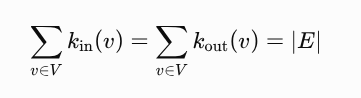

In [174]:

# validate node degrees against the number of unique edges

for name, degrees in node_degrees.items():
    expected_edges = len(all_edges[name])

    total_in = degrees["in_degree"].sum()
    total_out = degrees["out_degree"].sum()

    print(f"\n{name}")
    print(f"Unique edges: {expected_edges:,}")
    print(f"Total in-degree: {total_in:,}")
    print(f"Total out-degree: {total_out:,}")
    print(f"Degrees valid: {total_in == total_out == expected_edges}")



SWOW
Unique edges: 1,394,792
Total in-degree: 1,394,792
Total out-degree: 1,394,792
Degrees valid: True

Llama3
Unique edges: 795,231
Total in-degree: 795,231
Total out-degree: 795,231
Degrees valid: True

Mistral
Unique edges: 443,144
Total in-degree: 443,144
Total out-degree: 443,144
Degrees valid: True



#### Most Connected Nodes

After validating the node degrees, we can identify the nodes with the highest number of incoming and outgoing connections.

- **High in-degree:** A word appears as a response to many distinct cue words.
- **High out-degree:** A cue word is associated with many distinct responses.

These measures describe the connectivity of words in our directed semantic networks.

A high degree does not necessarily indicate greater semantic importance or cognitive relevance.


In [175]:

# identify the most connected nodes in each network

for name, df in node_degrees.items():
    print(f"\n{name}")

    print("\nTop 10 nodes by in-degree:")
    display(
        df.nlargest(10, "in_degree")[
            ["node", "in_degree", "out_degree"]
        ]
    )

    print("\nTop 10 nodes by out-degree:")
    display(
        df.nlargest(10, "out_degree")[
            ["node", "out_degree", "in_degree"]
        ]
    )



SWOW

Top 10 nodes by in-degree:


,node,in_degree,out_degree
128844,work,2193,130
41924,food,2130,144
72346,money,1982,135
44011,fun,1956,127
9033,bad,1940,129
68228,man,1920,116
66515,love,1887,144
94710,red,1885,125
47056,good,1850,150
125390,water,1831,118



Top 10 nodes by out-degree:


,node,out_degree,in_degree
89302,politics,191,741
93768,random,191,208
97591,rogue,188,72
29898,determination,187,109
19481,censorship,186,29
68440,manipulation,184,72
30679,diplomacy,181,39
88404,planning,180,124
121314,underdog,180,18
27858,dangerous,179,718



Llama3

Top 10 nodes by in-degree:


,node,in_degree,out_degree
58441,music,1162,73
82611,soft,946,76
86188,strong,910,49
35799,garden,825,67
33361,food,793,75
98330,water,754,104
1295,adventure,746,76
86514,style,707,74
30344,family,697,73
22134,design,673,76


... (2 outputs left out)


Mistral

Top 10 nodes by in-degree:


,node,in_degree,out_degree
7504,color,1082,26
25826,ocean,1075,40
4600,blue,1036,41
15154,fruit,1027,20
40595,water,1015,59
15282,furry,915,38
7809,computer,908,41
33980,sky,900,45
24295,music,874,24
17229,heart,854,12



Top 10 nodes by out-degree:


,node,out_degree,in_degree
36854,tad,129,2
27250,patsy,128,0
36213,suck,128,23
23472,minor,123,9
13965,filled,121,5
35534,status,121,37
26126,oodles,120,0
32284,sash,119,1
38605,tube,119,32
18166,hunk,117,6



#### In-Degree Distribution

After identifying the most connected nodes, we will examine how incoming connections are distributed across the semantic networks.

The in-degree of a node represents the number of distinct cue words that produce it as a response.

We want to investigate whether most nodes receive relatively few incoming connections, while a smaller number of nodes are associated with many different cues.

Since the networks contain nodes with very different degrees, we will use a logarithmic scale to make the distribution easier to visualize.


In [176]:

# compare in-degree distributions using logarithmic intervals

degree_data = pd.concat(
    [
        df[["node", "in_degree"]].assign(Dataset=name)
        for name, df in node_degrees.items()
    ],
    ignore_index=True
)

positive_degrees = degree_data[degree_data["in_degree"] > 0].copy()

max_degree = positive_degrees["in_degree"].max()
bins = np.logspace(0, np.log10(max_degree + 1), 25)

positive_degrees["degree_bin"] = pd.cut(
    positive_degrees["in_degree"],
    bins=bins,
    include_lowest=True
)

distribution = (
    positive_degrees
    .groupby(["Dataset", "degree_bin"], observed=True)
    .size()
    .rename("count")
    .reset_index()
)

distribution["probability"] = (
    distribution["count"]
    / distribution.groupby("Dataset")["count"].transform("sum")
)

distribution["bin_center"] = distribution["degree_bin"].apply(
    lambda interval: np.sqrt(interval.left * interval.right)
).astype(float)

fig = px.line(
    distribution,
    x="bin_center",
    y="probability",
    color="Dataset",
    markers=True,
    title="In-Degree Distribution by Dataset",
    color_discrete_map={
        "SWOW": "#3B82F6",
        "Llama3": "#10B981",
        "Mistral": "#F59E0B"
    }
)

fig.update_layout(
    xaxis_type="log",
    xaxis_title="In-degree (log scale)",
    yaxis_title="Probability per logarithmic interval",
    template="plotly_white"
)

fig.show()



**In-Degree Distribution : Observations:**

The graph shows the empirical distribution of in-degree values across the three semantic networks, using logarithmically spaced intervals.

Only nodes with at least one incoming connection are included.

**Observations:**

- **SWOW:** Most nodes have relatively low in-degree, but the distribution extends to values above 2,000.
- **Llama3:** Shows the highest concentration in the lowest in-degree interval, indicating that many nodes receive connections from very few distinct cue words.
- **Mistral:** Shows a lower concentration in the first interval and relatively higher proportions in several intermediate-degree intervals.
- **All datasets:** The distributions are strongly right-skewed, with many low-degree nodes and a small number of highly connected nodes.

**Interpretation:**

The results suggest that incoming connections are unevenly distributed across the semantic networks.

Most response words are associated with relatively few cue words, while some words act as common association targets for many different cues.

This pattern is consistent with the highly connected nodes identified earlier, such as `work` in SWOW, `music` in Llama3, and `color` in Mistral.

However, these observations do not establish that the networks follow a power-law distribution or are scale-free.

The results are descriptive and may also be influenced by vocabulary size, response generation, and differences in the number of unique edges.



#### Local Semantic Network Visualization

To illustrate how word associations are represented as networks, we will visualize the most frequent associations for the cue word `dog` . Each unique word is represented as a node, while each cue-response pair becomes a directed edge. The edge weight represents the observed frequency of that association. We will display the ten strongest outgoing associations for `dog` in each dataset.

These visualizations represent local network neighborhoods rather than the complete semantic networks.


In [177]:

import networkx as nx
import plotly.graph_objects as go

# build local semantic networks for a selected cue

selected_cue = "dog"
local_networks = {}

for name, edges in all_edges.items():
    top_edges = (
        edges[edges["source"] == selected_cue]
        .nlargest(10, "weight")
    )

    G = nx.DiGraph()
    
    for _, row in top_edges.iterrows():
        G.add_edge(
            row["source"],
            row["target"],
            weight=row["weight"]
        )

    local_networks[name] = G

    print(
        f"{name}: {G.number_of_nodes()} nodes, "
        f"{G.number_of_edges()} edges"
    )


SWOW: 11 nodes, 10 edges
Llama3: 11 nodes, 10 edges
Mistral: 11 nodes, 10 edges


In [178]:

# visualize local semantic networks with directed, weighted edges

network_colors = {
    "SWOW": "#3B82F6",
    "Llama3": "#10B981",
    "Mistral": "#F59E0B"
}

for name, G in local_networks.items():
    responses = list(G.successors(selected_cue))

    positions = {selected_cue: (0, 0)}

    for i, response in enumerate(responses):
        angle = 2 * np.pi * i / len(responses)
        positions[response] = (
            2 * np.cos(angle),
            2 * np.sin(angle)
        )

    fig = go.Figure()

    max_weight = max(
        data["weight"]
        for _, _, data in G.edges(data=True)
    )

    # total responses from the full edge list, not only the Top 10
    total_responses = all_edges[name].loc[
        all_edges[name]["source"] == selected_cue,
        "weight"
    ].sum()

    # draw weighted edges and direction arrows
    for source, target, data in G.edges(data=True):
        x0, y0 = positions[source]
        x1, y1 = positions[target]

        weight = data["weight"]
        edge_width = 1 + 5 * weight / max_weight
        probability = weight / total_responses

        hover_text = (
            f"{source} → {target}<br>"
            f"Weight: {weight}<br>"
            f"Empirical probability: {probability:.2%}"
        )

        # draw the edge
        fig.add_trace(go.Scatter(
            x=[x0, x1],
            y=[y0, y1],
            mode="lines",
            line=dict(
                width=edge_width,
                color="#94A3B8"
            ),
            hovertemplate=hover_text + "<extra></extra>",
            showlegend=False
        ))

        # add a transparent hover marker at the edge midpoint
        fig.add_trace(go.Scatter(
            x=[(x0 + x1) / 2],
            y=[(y0 + y1) / 2],
            mode="markers",
            marker=dict(
                size=16,
                color=network_colors[name],
                opacity=0.01
            ),
            hovertemplate=hover_text + "<extra></extra>",
            showlegend=False
        ))

        # Arrowhead near the response node
        fig.add_annotation(
            x=x1 * 0.88,
            y=y1 * 0.88,
            ax=x0,
            ay=y0,
            xref="x",
            yref="y",
            axref="x",
            ayref="y",
            text="",
            showarrow=True,
            arrowhead=2,
            arrowsize=1,
            arrowwidth=1.5,
            arrowcolor=network_colors[name]
        )

    # draw nodes
    for node in G.nodes():
        x, y = positions[node]

        fig.add_trace(go.Scatter(
            x=[x],
            y=[y],
            mode="markers+text",
            marker=dict(
                size=30 if node == selected_cue else 20,
                color=(
                    network_colors[name]
                    if node == selected_cue
                    else "#CBD5E1"
                ),
                line=dict(width=1, color="#FFFFFF")
            ),
            text=[node],
            textposition="top center",
            hovertext=node,
            hoverinfo="text",
            showlegend=False
        ))

    # configure the completed figure
    fig.update_layout(
        title=f"{name} - Local Semantic Network for '{selected_cue}'",
        template="plotly_white",
        xaxis=dict(
            visible=False,
            range=[-2.6, 2.6]
        ),
        yaxis=dict(
            visible=False,
            range=[-2.5, 2.5],
            scaleanchor="x",
            scaleratio=1
        ),
        height=600,
        margin=dict(l=20, r=20, t=70, b=20),
        hovermode="closest"
    )

    fig.show()



**Local Semantic Networks - Observations:**

The visualizations show the ten strongest outgoing associations for the cue word `dog` in SWOW, Llama3, and Mistral.

Each network is represented using:

- **Nodes:** Unique words appearing as cues or responses.
- **Directed edges:** Associations from the cue word to its responses.
- **Edge weights:** Observed frequencies of individual cue-response associations.

**Understanding Weighted Edges:**

Thicker edges indicate associations that were observed more frequently.

For example, in SWOW, the connection `dog → cat` is thicker than `dog → pet` because `cat` was produced more frequently as a response to `dog`.

Therefore, edge thickness visually represents the observed association frequency.

The empirical probability of an association is calculated as:

$$
P(r \mid c) = \frac{w(c,r)}{\sum_{r'} w(c,r')}
$$

Where:

- $c$ = cue word.
- $r$ = response word.
- $w(c,r)$ = observed frequency (weight) of the directed edge from $c$ to $r$.
- $\sum_{r'} w(c,r')$ = total number of valid responses associated with cue $c$.

The hover information displays both the edge weight and its empirical probability, calculated using all valid responses for the selected cue.

**Observations:**

- **SWOW:** The strongest association for `dog` is `cat` (17.59%), followed by `pet` and `friend`. The responses include other animals, relationships, and characteristics associated with dogs.

- **Llama3:** The strongest association is `fetch` (3.67%). The top associations have relatively similar frequencies, indicating a less dominant leading response compared with SWOW and Mistral.

- **Mistral:** The strongest association is `bark` (18.62%), followed by associations related to physical characteristics and typical behaviors, such as `furry`, `fur`, and `play`.

**Interpretation:**

The three local networks show different dominant associations for the same cue word.

SWOW primarily associates `dog` with another animal (`cat`), Llama3 with an activity (`fetch`), and Mistral with a typical behavior (`bark`).

Despite these differences, several responses overlap across datasets, including `puppy`, `animal`, and `bark`.

These observations illustrate differences in lexical choices and association frequencies between human and LLM-generated responses.

**Limitations:**

- Edge thickness is normalized separately within each network. Therefore, thicknesses should not be directly compared across datasets.
- The radial layout is used for readability and does not represent semantic similarity or distance.
- Only the ten strongest outgoing associations are displayed, rather than the complete semantic networks.
- Connections between the response nodes are not displayed, even if they exist in the complete networks.
- The results describe a single cue word and should not be generalized to the entire dataset without further analysis.

These visualizations illustrate how word associations can be transformed into directed, weighted semantic networks, but do not establish differences in cognitive mechanisms.



### 6.3 Exploratory Findings

In this section, we investigated relationships between lexical features and explored the structural properties of the semantic networks constructed from SWOW, Llama3, and Mistral.

**Main Findings:**

**1. Feature Relationships**

- All three datasets show a negative monotonic relationship between association diversity and top response proportion.
- The Spearman correlation coefficients were -0.5971 for SWOW, -0.6523 for Llama3, and -0.6167 for Mistral.
- This indicates that cue words with higher lexical diversity generally have a lower concentration around their most frequent response.
- Since both features are derived from the same response frequencies, part of this relationship may result from their mathematical definitions.

**2. Network Connectivity**

- The directed semantic networks contain 130,539 nodes in SWOW, 101,689 in Llama3, and 42,058 in Mistral.
- The calculated in-degree and out-degree totals match the number of unique directed edges in each network.
- The in-degree distributions are strongly right-skewed: most nodes receive connections from relatively few cue words, while a smaller number of nodes receive connections from many different cues.
- Highly connected response nodes include `work` in SWOW, `music` in Llama3, and `color` in Mistral.

**3. Local Semantic Network Patterns**

- The local networks for `dog` illustrate how cue-response associations can be represented as directed, weighted edges.
- The strongest outgoing association differs across datasets: `cat` in SWOW, `fetch` in Llama3, and `bark` in Mistral.
- Edge weights represent observed association frequencies, while empirical probabilities describe the proportion of responses assigned to each association.
- The visualizations highlight both shared response vocabulary and differences in the most frequent associations.

**Limitations:**

These findings are exploratory and descriptive.

Differences in vocabulary size, response availability, and data collection or generation procedures may influence the observed network properties.

Furthermore, the relationships between engineered features and the local network examples do not establish differences in semantic understanding or cognitive mechanisms.

**Next Steps:**

In Section 7, we will perform more controlled comparisons using cue words shared across the three datasets.

This will allow us to investigate whether the observed differences in lexical diversity and association patterns remain consistent when comparing the same stimuli.



## 7. Comparative Exploratory Data Analysis

In the previous sections, we explored the lexical and structural properties of SWOW, Llama3, and Mistral.

However, the datasets do not contain exactly the same cue words, and the number of valid responses can differ between them.

To make our comparisons more meaningful, we will focus on cue words shared across all three datasets.

This allows us to compare human and LLM-generated associations for the same stimuli.

We will investigate differences in lexical diversity, response concentration, and response overlap.

These comparisons control for cue-word selection, but differences in response counts and data collection or generation procedures must still be considered.



### 7.1 Shared Cue Words

We first identify the cue words that appear in all three cleaned datasets.

Using a common set of cue words ensures that subsequent analyses compare the same stimuli rather than different vocabularies.

The intersection of the cue sets is defined as:

$$
C_{\text{shared}} =
C_{\text{SWOW}} \cap C_{\text{Llama3}} \cap C_{\text{Mistral}}
$$

Where each set contains the unique cue words from the corresponding cleaned dataset.

We will then restrict the previously engineered cue-level features to this shared vocabulary.


In [179]:

# identify shared cue words across cleaned datasets

cleaned_cue_sets = {
    name: set(df["cue"].dropna().unique())
    for name, df in cleaned_datasets.items()
}

shared_cues = set.intersection(*cleaned_cue_sets.values())

print(f"Shared cue words: {len(shared_cues):,}")

for name, cues in cleaned_cue_sets.items():
    print(
        f"{name}: {len(cues):,} unique cues, "
        f"{len(shared_cues) / len(cues):.2%} shared"
    )


Shared cue words: 11,483
SWOW: 12,282 unique cues, 93.49% shared
Llama3: 11,545 unique cues, 99.46% shared
Mistral: 11,545 unique cues, 99.46% shared


In [180]:

# restrict engineered cue-level features to shared cue words

shared_cue_features = {}

for name, df in cue_features.items():
    shared_cue_features[name] = (
        df[df["cue"].isin(shared_cues)]
        .copy()
        .reset_index(drop=True)
    )

    print(
        f"{name}: {len(shared_cue_features[name]):,} "
        "cues with valid responses"
    )


SWOW: 11,483 cues with valid responses
Llama3: 11,298 cues with valid responses
Mistral: 11,330 cues with valid responses



#### Final Aligned Cue Set

Although 11,483 cue words are shared across the cleaned datasets, some do not have valid responses in the LLM-generated datasets.

For consistent cue-level comparisons, we restrict the analysis to cue words with at least one valid response in all three datasets.

This ensures that every cue included in the comparative analysis has corresponding engineered features in SWOW, Llama3, and Mistral.

The resulting datasets will contain exactly the same cue words, allowing paired comparisons across sources.


In [181]:

# identify cues with valid responses in all three datasets

valid_cue_sets = {
    name: set(df["cue"])
    for name, df in shared_cue_features.items()
}

aligned_cues = set.intersection(*valid_cue_sets.values())

aligned_cue_features = {
    name: (
        df[df["cue"].isin(aligned_cues)]
        .sort_values("cue")
        .reset_index(drop=True)
    )
    for name, df in shared_cue_features.items()
}

print(f"Final aligned cue words: {len(aligned_cues):,}")

for name, df in aligned_cue_features.items():
    print(f"{name}: {len(df):,} cues")

# verify identical cue ordering
reference = aligned_cue_features["SWOW"]["cue"]

alignment_valid = all(
    df["cue"].equals(reference)
    for df in aligned_cue_features.values()
)

print(f"Alignment valid: {alignment_valid}")


Final aligned cue words: 11,298
SWOW: 11,298 cues
Llama3: 11,298 cues
Mistral: 11,298 cues
Alignment valid: True



**Shared Cue Words : Observations:**

After cleaning and normalizing the datasets, we identified 11,483 cue words shared across SWOW, Llama3, and Mistral.

However, not every shared cue has valid responses in all three datasets.

To ensure consistent comparisons, we constructed a final aligned subset containing **11,298 cue words** with valid responses in every dataset.

All three feature tables contain the same cue words in identical order, and the alignment validation passed.

This allows us to perform paired comparisons on the same stimuli, reducing differences caused by unequal cue vocabularies.

However, cue alignment does not eliminate differences in response counts or data collection and generation procedures.



### 7.2 Comparative Feature Analysis

We now compare lexical features across the 11,298 aligned cue words.

Since each cue appears in all three datasets, we can examine differences between human and LLM-generated associations for the same stimulus.

We begin with association diversity, defined as the proportion of unique responses among all valid responses for a cue.

#### Paired Association Diversity Comparison

For each shared cue word, we calculate the difference in observed association diversity between SWOW and each LLM dataset.

$$
\Delta D(c) = D_{\text{SWOW}}(c) - D_{\text{LLM}}(c)
$$

Where:

- $D_{\text{SWOW}}(c)$ = association diversity for cue $c$ in SWOW.
- $D_{\text{LLM}}(c)$ = association diversity for the same cue in Llama3 or Mistral.
- $\Delta D(c) > 0$ indicates higher observed diversity in SWOW.
- $\Delta D(c) < 0$ indicates higher observed diversity in the LLM dataset.

These comparisons are descriptive and do not yet control for differences in the number of valid responses.


In [182]:

# compare association diversity for aligned cue words

diversity_comparison = pd.DataFrame({
    "cue": aligned_cue_features["SWOW"]["cue"],
    "SWOW": aligned_cue_features["SWOW"]["association_diversity"],
    "Llama3": aligned_cue_features["Llama3"]["association_diversity"],
    "Mistral": aligned_cue_features["Mistral"]["association_diversity"]
})

diversity_comparison["SWOW_vs_Llama3"] = (
    diversity_comparison["SWOW"] - diversity_comparison["Llama3"]
)

diversity_comparison["SWOW_vs_Mistral"] = (
    diversity_comparison["SWOW"] - diversity_comparison["Mistral"]
)

display(diversity_comparison.head(10))


,cue,SWOW,Llama3,Mistral,SWOW_vs_Llama3,SWOW_vs_Mistral
0,a,0.433333,0.443333,0.366379,-0.010000,0.066954
1,a few,0.390335,0.193333,0.298429,0.197001,0.091905
2,a little,0.317164,0.140000,0.192982,0.177164,0.124182
3,a lot,0.367857,0.306667,0.239496,0.061190,0.128361
4,aardvark,0.434944,0.210000,0.171756,0.224944,0.263189
5,abacus,0.333333,0.256667,0.063333,0.076667,0.270000
6,abandon,0.426523,0.246667,0.137809,0.179857,0.288714
7,abbey,0.390071,0.190000,0.134680,0.200071,0.255391
8,abbreviation,0.475472,0.165000,0.156028,0.310472,0.319443
9,abdicate,0.378601,0.296667,0.121951,0.081934,0.256650


In [183]:

from plotly.subplots import make_subplots

# visualize paired association diversity comparisons

fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=[
        "SWOW vs. Llama3",
        "SWOW vs. Mistral"
    ],
    horizontal_spacing=0.12
)

for col, (name, color) in enumerate(
    [
        ("Llama3", "#10B981"),
        ("Mistral", "#F59E0B")
    ],
    start=1
):
    fig.add_trace(
        go.Scatter(
            x=diversity_comparison["SWOW"],
            y=diversity_comparison[name],
            mode="markers",
            marker=dict(
                color=color,
                size=5,
                opacity=0.25
            ),
            text=diversity_comparison["cue"],
            hovertemplate=(
                "Cue: %{text}<br>"
                "SWOW: %{x:.3f}<br>"
                f"{name}: %{{y:.3f}}"
                "<extra></extra>"
            ),
            showlegend=False
        ),
        row=1,
        col=col
    )

    # Equality reference line
    fig.add_trace(
        go.Scatter(
            x=[0, 1],
            y=[0, 1],
            mode="lines",
            line=dict(
                color="#64748B",
                dash="dash"
            ),
            showlegend=False,
            hoverinfo="skip"
        ),
        row=1,
        col=col
    )

fig.update_xaxes(
    title_text="SWOW association diversity",
    range=[0, 1]
)

fig.update_yaxes(
    title_text="LLM association diversity",
    range=[0, 1]
)

fig.update_layout(
    title="Paired Association Diversity Comparison",
    template="plotly_white",
    height=550
)

fig.show()


In [184]:

# summarize paired association diversity differences

for name in ["Llama3", "Mistral"]:
    difference = diversity_comparison["SWOW"] - diversity_comparison[name]

    swow_higher = (difference > 0).mean() * 100
    llm_higher = (difference < 0).mean() * 100
    equal = (difference == 0).mean() * 100

    print(f"\nSWOW vs. {name}")
    print(f"Mean difference: {difference.mean():.4f}")
    print(f"Median difference: {difference.median():.4f}")
    print(f"SWOW higher: {swow_higher:.2f}%")
    print(f"{name} higher: {llm_higher:.2f}%")
    print(f"Equal: {equal:.2f}%")



SWOW vs. Llama3
Mean difference: 0.1720
Median difference: 0.1695
SWOW higher: 94.18%
Llama3 higher: 5.80%
Equal: 0.02%

SWOW vs. Mistral
Mean difference: 0.2730
Median difference: 0.2725
SWOW higher: 99.34%
Mistral higher: 0.66%
Equal: 0.00%



#### Response Count Comparability

The paired comparison shows higher observed association diversity in SWOW for most shared cue words.

However, association diversity depends on the number of valid responses available for each cue.

Before interpreting these differences, we examine whether response counts are comparable across the aligned datasets.

This allows us to identify potential sampling-related differences that may influence the observed diversity ratios.


In [185]:

# compare response counts for aligned cue words

response_count_comparison = pd.DataFrame({
    "cue": aligned_cue_features["SWOW"]["cue"],
    "SWOW": aligned_cue_features["SWOW"]["response_count"],
    "Llama3": aligned_cue_features["Llama3"]["response_count"],
    "Mistral": aligned_cue_features["Mistral"]["response_count"]
})

print("Response count summary:")
display(
    response_count_comparison[
        ["SWOW", "Llama3", "Mistral"]
    ].agg(["mean", "median", "std", "min", "max"]).round(2)
)

print("\nCues with 300 valid responses:")
for name in ["SWOW", "Llama3", "Mistral"]:
    percentage = (
        response_count_comparison[name].eq(300).mean() * 100
    )
    print(f"{name}: {percentage:.2f}%")


Response count summary:


,SWOW,Llama3,Mistral
mean,276.85,294.73,286.89
median,282.00,300.00,292.00
std,17.67,23.13,18.15
min,115.00,12.00,24.00
max,300.00,300.00,300.00



Cues with 300 valid responses:
SWOW: 0.16%
Llama3: 81.58%
Mistral: 6.73%



#### Equal-Size Response Sampling

Although the cue words are aligned, the datasets contain different numbers of valid responses per cue.

To reduce the influence of sample size on association diversity, we will compare equal-sized samples of responses.

We propose sampling 100 valid responses without replacement for each cue word in all three datasets.

Only cues with at least 100 valid responses in every dataset will be included.

This provides a more comparable descriptive estimate of lexical diversity, although differences in data collection and response generation procedures remain.


In [186]:

# check eligibility for equal-size response sampling

sample_size = 100

eligible_mask = (
    response_count_comparison[
        ["SWOW", "Llama3", "Mistral"]
    ].ge(sample_size).all(axis=1)
)

eligible_cues = set(
    response_count_comparison.loc[eligible_mask, "cue"]
)

print(f"Aligned cues: {len(response_count_comparison):,}")
print(f"Eligible cues (>= {sample_size} responses): {len(eligible_cues):,}")
print(f"Excluded cues: {(~eligible_mask).sum():,}")
print(f"Eligibility rate: {eligible_mask.mean():.2%}")


Aligned cues: 11,298
Eligible cues (>= 100 responses): 11,243
Excluded cues: 55
Eligibility rate: 99.51%



#### Equal-Size Association Diversity

We now estimate association diversity using equal-sized response samples for the 11,243 eligible cue words.

For each cue and dataset, we randomly select 100 valid responses without replacement.

Association diversity is then recalculated as:

$$
D_{100}(c) = \frac{U_{100}(c)}{100}
$$

Where $U_{100}(c)$ represents the number of distinct responses observed in the sampled set.

Sampling is performed from the individual response observations, preserving repeated associations.

We use a fixed random seed to make the results reproducible.

This analysis controls the number of sampled responses per cue, but it does not eliminate differences in how human and LLM responses were collected or generated.


In [187]:

# sample 100 valid responses per eligible cue and dataset

sampled_diversity = {}

for name, df in all_long.items():
    eligible_df = df[df["cue"].isin(eligible_cues)].copy()

    shuffled = eligible_df.sample(
        frac=1,
        random_state=42
    )

    sampled = (
        shuffled.groupby("cue", sort=False)
        .head(sample_size)
    )

    diversity = (
        sampled.groupby("cue")["response"]
        .nunique()
        .div(sample_size)
        .rename("sampled_diversity")
        .reset_index()
        .sort_values("cue")
        .reset_index(drop=True)
    )

    sampled_diversity[name] = diversity

    print(
        f"{name}: {len(diversity):,} cues, "
        f"mean sampled diversity = "
        f"{diversity['sampled_diversity'].mean():.4f}"
    )


SWOW: 11,243 cues, mean sampled diversity = 0.5449
Llama3: 11,243 cues, mean sampled diversity = 0.5148
Mistral: 11,243 cues, mean sampled diversity = 0.2345


In [188]:

# debug: validate sampled diversity calculations

for name, df in sampled_diversity.items():
    valid = (
        len(df) == len(eligible_cues)
        and df["cue"].is_unique
        and df["sampled_diversity"].between(0.01, 1).all()
        and set(df["cue"]) == eligible_cues
    )

    print(f"{name}: sampling valid = {valid}")


SWOW: sampling valid = True
Llama3: sampling valid = True
Mistral: sampling valid = True



#### Paired Diversity Comparison After Equal-Size Sampling

After sampling 100 responses per cue, we obtained the following mean association diversity values:

- **SWOW:** 0.5449
- **Llama3:** 0.5148
- **Mistral:** 0.2345

The difference between SWOW and Llama3 is substantially smaller than in the original paired comparison, while the difference between SWOW and Mistral remains pronounced.

We now compare the sampled diversity values for individual cue words to examine how consistently these differences appear across the aligned datasets.

Each point represents the same cue word in two datasets, with 100 sampled responses per cue in each dataset.


In [189]:

# build paired comparison from equal-size sampled diversity

sampled_comparison = (
    sampled_diversity["SWOW"]
    .rename(columns={"sampled_diversity": "SWOW"})
    .merge(
        sampled_diversity["Llama3"].rename(
            columns={"sampled_diversity": "Llama3"}
        ),
        on="cue",
        validate="one_to_one"
    )
    .merge(
        sampled_diversity["Mistral"].rename(
            columns={"sampled_diversity": "Mistral"}
        ),
        on="cue",
        validate="one_to_one"
    )
)

display(sampled_comparison.head(10))


,cue,SWOW,Llama3,Mistral
0,a,0.55,0.66,0.50
1,a few,0.51,0.43,0.39
2,a little,0.40,0.36,0.34
3,a lot,0.49,0.58,0.32
4,aardvark,0.49,0.52,0.31
5,abacus,0.36,0.58,0.15
6,abandon,0.52,0.58,0.29
7,abbey,0.54,0.47,0.26
8,abbreviation,0.68,0.31,0.29
9,abdicate,0.52,0.64,0.23


In [190]:

# compare association diversity after equal-size sampling

fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=[
        "SWOW vs. Llama3",
        "SWOW vs. Mistral"
    ],
    horizontal_spacing=0.12
)

for col, (name, color) in enumerate(
    [
        ("Llama3", "#10B981"),
        ("Mistral", "#F59E0B")
    ],
    start=1
):
    fig.add_trace(
        go.Scatter(
            x=sampled_comparison["SWOW"],
            y=sampled_comparison[name],
            mode="markers",
            marker=dict(
                color=color,
                size=5,
                opacity=0.25
            ),
            text=sampled_comparison["cue"],
            hovertemplate=(
                "Cue: %{text}<br>"
                "SWOW: %{x:.3f}<br>"
                f"{name}: %{{y:.3f}}"
                "<extra></extra>"
            ),
            showlegend=False
        ),
        row=1,
        col=col
    )

    # euality reference line
    fig.add_trace(
        go.Scatter(
            x=[0, 1],
            y=[0, 1],
            mode="lines",
            line=dict(
                color="#64748B",
                dash="dash"
            ),
            hoverinfo="skip",
            showlegend=False
        ),
        row=1,
        col=col
    )

fig.update_xaxes(
    title_text="SWOW sampled diversity",
    range=[0, 1]
)

fig.update_yaxes(
    title_text="LLM sampled diversity",
    range=[0, 1]
)

fig.update_layout(
    title="Paired Association Diversity (100 Responses per Cue)",
    template="plotly_white",
    height=550
)

fig.show()


In [191]:

# summarize paired diversity differences after equal-size sampling

for name in ["Llama3", "Mistral"]:
    difference = sampled_comparison["SWOW"] - sampled_comparison[name]

    print(f"\nSWOW vs. {name}")
    print(f"Mean difference: {difference.mean():.4f}")
    print(f"Median difference: {difference.median():.4f}")
    print(f"SWOW higher: {(difference > 0).mean():.2%}")
    print(f"{name} higher: {(difference < 0).mean():.2%}")
    print(f"Equal: {(difference == 0).mean():.2%}")



SWOW vs. Llama3
Mean difference: 0.0301
Median difference: 0.0100
SWOW higher: 51.22%
Llama3 higher: 45.98%
Equal: 2.80%

SWOW vs. Mistral
Mean difference: 0.3105
Median difference: 0.3100
SWOW higher: 99.16%
Mistral higher: 0.70%
Equal: 0.13%



**Comparative Association Diversity - Observations:**

We compared association diversity across shared cue words, first using all available valid responses and then using equal-sized samples of 100 responses per cue.

**1. Original Paired Comparison**

Across 11,298 aligned cue words:

- **SWOW vs. Llama3:** SWOW showed higher association diversity for 94.18% of cues, with a mean difference of 0.1720.
- **SWOW vs. Mistral:** SWOW showed higher association diversity for 99.34% of cues, with a mean difference of 0.2730.

These results initially suggested substantially higher observed lexical diversity in SWOW.

However, the datasets contained different numbers of valid responses per cue, potentially influencing the diversity ratios.

**2. Equal-Size Response Sampling**

To reduce this influence, we sampled 100 valid responses without replacement for each of the 11,243 eligible cue words.

The resulting mean association diversity values were:

- **SWOW:** 0.5449
- **Llama3:** 0.5148
- **Mistral:** 0.2345

The paired comparisons revealed:

- **SWOW vs. Llama3:** The mean difference decreased to 0.0301. SWOW showed higher diversity for 51.22% of cues, while Llama3 showed higher diversity for 45.98%.
- **SWOW vs. Mistral:** The mean difference remained substantial at 0.3105, with SWOW showing higher diversity for 99.16% of cues.

**3. Interpretation**

After equalizing the number of sampled responses, SWOW and Llama3 showed much more similar levels of lexical diversity.

This suggests that the original diversity comparison was sensitive to response sample size, and that unequal response counts contributed to the observed differences.

In contrast, Mistral continued to exhibit substantially lower association diversity for nearly all shared cue words.

The paired scatter plots support these findings: SWOW and Llama3 show considerable overlap around the equality line, while Mistral remains predominantly below it.

**4. Limitations**

- The original and sampled comparisons use slightly different cue subsets (11,298 versus 11,243), so their differences cannot be attributed exclusively to sample-size control.
- Sampling was performed using a single fixed random seed. The variability across repeated samples was not evaluated.
- Equalizing response counts does not eliminate methodological differences in human data collection and LLM response generation.
- Similar lexical diversity does not necessarily imply similar response content or semantic organization.




### 7.3 Response Overlap

In the previous section, we compared lexical diversity between SWOW, Llama3, and Mistral.

However, similar levels of lexical diversity do not necessarily imply that the datasets contain the same responses.

We now investigate how many distinct LLM-generated responses also appear in SWOW for the same cue word.

For each shared cue, we compare the sets of unique responses using exact textual matching.

The response overlap percentage is defined as:

$$
O(c) = \frac{|R_{\text{LLM}}(c) \cap R_{\text{SWOW}}(c)|}{|R_{\text{LLM}}(c)|} \times 100
$$

Where:

- $c$ = a shared cue word.
- $R_{\text{LLM}}(c)$ = the set of distinct responses generated by the LLM for cue $c$.
- $R_{\text{SWOW}}(c)$ = the set of distinct human responses for the same cue.
- $\cap$ = set intersection, representing responses present in both datasets.
- $|R|$ = the number of elements in a set.

An overlap of 100% means that every distinct LLM response also appears in SWOW.

An overlap of 0% means that none of the distinct LLM responses appears in SWOW.

This measure is directional: it describes the proportion of LLM responses found in SWOW, not the proportion of SWOW responses found in the LLM dataset.


In [192]:

# build unique response sets for aligned cue words

response_sets = {}

for name, df in all_long.items():
    aligned_df = df[df["cue"].isin(aligned_cues)]

    response_sets[name] = (
        aligned_df.groupby("cue")["response"]
        .agg(set)
        .to_dict()
    )

    print(
        f"{name}: {len(response_sets[name]):,} "
        "cue words with response sets"
    )


SWOW: 11,298 cue words with response sets
Llama3: 11,298 cue words with response sets
Mistral: 11,298 cue words with response sets


In [193]:

# compute response overlap with SWOW for each LLM

overlap_results = []

for name in ["Llama3", "Mistral"]:
    for cue in sorted(aligned_cues):
        swow_responses = response_sets["SWOW"][cue]
        llm_responses = response_sets[name][cue]

        shared_responses = swow_responses & llm_responses

        overlap_results.append({
            "cue": cue,
            "dataset": name,
            "shared_responses": len(shared_responses),
            "llm_unique_responses": len(llm_responses),
            "overlap_percentage": (
                len(shared_responses) / len(llm_responses) * 100
            )
        })

overlap_df = pd.DataFrame(overlap_results)

display(overlap_df.head(10))


,cue,dataset,shared_responses,llm_unique_responses,overlap_percentage
0,a,Llama3,7,133,5.263158
1,a few,Llama3,10,58,17.241379
2,a little,Llama3,11,42,26.190476
3,a lot,Llama3,12,92,13.043478
4,aardvark,Llama3,7,63,11.111111
5,abacus,Llama3,18,77,23.376623
6,abandon,Llama3,9,74,12.162162
7,abbey,Llama3,12,57,21.052632
8,abbreviation,Llama3,9,33,27.272727
9,abdicate,Llama3,7,89,7.865169


In [194]:

# summarize response overlap with SWOW

overlap_summary = (
    overlap_df.groupby("dataset")["overlap_percentage"]
    .agg(["mean", "median", "std", "min", "max"])
    .round(2)
)

display(overlap_summary)

print("\nCues with no shared responses:")

for name, df in overlap_df.groupby("dataset"):
    zero_overlap = df["overlap_percentage"].eq(0).mean() * 100

    print(f"{name}: {zero_overlap:.2f}%")


,mean,median,std,min,max
dataset,,,,,
Llama3,21.26,20.00,9.80,0.0,85.71
Mistral,42.48,42.11,13.58,0.0,100.00



Cues with no shared responses:
Llama3: 0.50%
Mistral: 0.05%



#### Empirical Response Overlap Distribution

We compare the empirical distributions of response overlap percentages for Llama3 and Mistral.

Each cue word contributes one overlap percentage to each dataset.

We divide the percentages into intervals of 5 percentage points and calculate the proportion of cue words falling within each interval.

This allows us to compare the distribution of lexical overlap with SWOW across the two LLMs.


In [195]:

# compare empirical distributions of response overlap

bins = np.arange(0, 105, 5)
bin_centers = (bins[:-1] + bins[1:]) / 2

fig = go.Figure()

for name, color in [
    ("Llama3", "#10B981"),
    ("Mistral", "#F59E0B")
]:
    values = overlap_df.loc[
        overlap_df["dataset"] == name,
        "overlap_percentage"
    ]

    counts, _ = np.histogram(values, bins=bins)
    probabilities = counts / counts.sum()

    fig.add_trace(go.Bar(
        x=bin_centers,
        y=probabilities,
        name=name,
        marker_color=color,
        width=2.2,
        hovertemplate=(
            "Overlap interval: %{customdata}<br>"
            "Probability: %{y:.2%}"
            "<extra></extra>"
        ),
        customdata=[
            f"{bins[i]}-{bins[i+1]}%"
            for i in range(len(counts))
        ]
    ))

fig.update_layout(
    title="Empirical Distribution of Response Overlap with SWOW",
    xaxis_title="Response overlap (%)",
    yaxis_title="Probability",
    xaxis_range=[0, 100],
    yaxis_tickformat=".0%",
    barmode="group",
    template="plotly_white",
    height=500
)

fig.show()



**Response Overlap - Observations:**

We compared the proportion of distinct LLM responses that also appear in SWOW for each of the 11,298 aligned cue words.

The comparison uses exact textual matching between response sets.

**Descriptive Statistics:**

- **Llama3:** Mean overlap of 21.26%, median of 20.00%, and standard deviation of 9.80 percentage points.
- **Mistral:** Mean overlap of 42.48%, median of 42.11%, and standard deviation of 13.58 percentage points.
- Only 0.50% of Llama3 cues and 0.05% of Mistral cues have no responses in common with SWOW.

**Empirical Distribution - Observations:**

- **Llama3:** Most overlap percentages are concentrated around 10–30%, with the highest concentration near 15–20%.
- **Mistral:** The distribution is shifted toward higher overlap percentages, with many cue words between 30% and 55%.
- **Both datasets:** The distributions overlap, but Mistral generally shows higher response overlap with SWOW.

The histogram represents the proportion of cue words falling into each 5-percentage-point interval.

**Interpretation:**

Mistral produces a higher proportion of distinct responses that are also observed in SWOW compared with Llama3.

This result is particularly interesting when compared with the findings from Section 7.2.

After equal-size sampling (100 responses per cue), the mean association diversity values were:

- **SWOW:** 0.5449
- **Llama3:** 0.5148
- **Mistral:** 0.2345

SWOW and Llama3 exhibited relatively similar levels of lexical diversity, while Mistral showed substantially lower diversity.

However, the response overlap analysis reveals a different pattern:

- **Llama3:** 21.26% mean response overlap with SWOW.
- **Mistral:** 42.48% mean response overlap with SWOW.

This demonstrates that lexical diversity and response overlap capture different properties:

- **Association diversity:** How varied the responses are within a dataset.
- **Response overlap:** What proportion of distinct LLM responses also appear in the human association dataset.

Therefore, although Llama3 produces a more diverse set of responses, Mistral produces a higher proportion of responses that are also present in SWOW.

These findings suggest that higher lexical diversity does not necessarily correspond to higher lexical agreement with human responses.

**Limitations:**

- The overlap percentage is directional and uses the number of distinct LLM responses as its denominator.
- Differences in response-set sizes can influence the observed overlap percentages.
- Only exact textual matches are counted; semantically related expressions with different wording are treated as distinct.
- The diversity comparison in Section 7.2 uses equal-size samples of 100 responses per cue, while the overlap analysis uses all valid distinct responses.
- Equal-size diversity was evaluated on 11,243 eligible cue words, whereas response overlap was evaluated on all 11,298 aligned cue words.
- Higher lexical overlap does not necessarily indicate greater cognitive or semantic similarity.

**Conclusion:**

Mistral shows substantially higher exact lexical response overlap with SWOW than Llama3, despite having lower observed association diversity.

This highlights the importance of examining both response diversity and response content when comparing human and LLM-generated semantic associations.

The comparison remains descriptive, and the results should be interpreted in the context of differences in response-set sizes and data collection or generation procedures.



### 7.4 Comparative Findings

This section summarizes the main findings from the comparative analysis of human and LLM-generated word associations.

The analysis focused on shared cue words, lexical diversity, and exact response overlap between SWOW, Llama3, and Mistral.

#### 1. Shared Cue Words

After text normalization, we identified **11,483 cue words** shared across all three datasets.

Of these, **11,298 cue words** had valid responses in every dataset and were retained for paired comparisons.

This allowed us to compare responses to identical stimuli, reducing differences caused by unequal cue vocabularies.

However, the number of valid responses per cue still varied between datasets.

#### 2. Association Diversity

The initial paired comparison showed substantially higher observed association diversity in SWOW:

- **SWOW vs. Llama3:** SWOW had higher diversity for 94.18% of aligned cues.
- **SWOW vs. Mistral:** SWOW had higher diversity for 99.34% of aligned cues.

However, response counts were not identical across datasets.

To investigate the influence of sample size, we selected **11,243 eligible cue words** and randomly sampled 100 valid responses per cue in each dataset.

The resulting mean association diversity values were:

- **SWOW:** 0.5449
- **Llama3:** 0.5148
- **Mistral:** 0.2345

After equal-size sampling:

- The mean SWOW–Llama3 diversity difference decreased to **0.0301**.
- SWOW showed higher diversity than Llama3 for **51.22%** of cues, while Llama3 showed higher diversity for **45.98%**.
- The mean SWOW–Mistral diversity difference remained substantial at **0.3105**.
- SWOW showed higher diversity than Mistral for **99.16%** of cues.

These results show that the observed SWOW–Llama3 diversity difference is highly sensitive to response sample size and cue-subset selection.

In contrast, Mistral continued to exhibit substantially lower lexical diversity under equal-size sampling.

#### 3. Response Overlap

We also examined the proportion of distinct LLM responses that appeared in SWOW for the same cue word.

The mean exact lexical response overlap was:

- **Llama3:** 21.26%
- **Mistral:** 42.48%

Mistral exhibited higher response overlap with SWOW, despite producing less diverse responses than Llama3.

This reveals an important distinction between two properties of semantic association datasets:

- **Lexical diversity** measures how many different responses are produced relative to the total number of responses.
- **Response overlap** measures what proportion of distinct LLM responses are also present in SWOW.

Therefore, higher lexical diversity does not necessarily correspond to higher lexical agreement with human responses.

#### 4. Methodological Limitations

The findings should be interpreted with several limitations in mind:

- **Response sample size:** Association diversity depends on the number of valid responses per cue.
- **Sampling variability:** Equal-size diversity was estimated using one random sample with a fixed seed. Repeated sampling was not evaluated.
- **Cue selection:** The equal-size analysis excluded 55 cues that did not have at least 100 valid responses in every dataset.
- **Response-set size:** The overlap percentage is directional and may be influenced by differences in the number of distinct LLM responses.
- **Exact matching:** Response overlap considers only identical text, without accounting for synonyms or semantic equivalence.
- **Data generation:** Human associations and LLM-generated responses were collected through different procedures, which may influence their distributions.

Consequently, the observed differences should not be interpreted as direct evidence of differences in cognitive mechanisms or semantic understanding.

#### 5. Overall Interpretation

The comparative analysis highlights three main findings:

1. **Cue alignment matters:** Comparing identical stimuli provides a more consistent basis for evaluating human and LLM-generated associations.

2. **Sample size matters:** After equalizing the number of responses, SWOW and Llama3 showed much more similar lexical diversity, while Mistral remained considerably less diverse.

3. **Diversity and overlap describe different properties:** Mistral showed greater exact response overlap with SWOW despite having lower lexical diversity than Llama3.

Together, these findings demonstrate that no single descriptive metric fully captures the relationship between human and LLM-generated word associations.

A meaningful comparison should consider both the variety of responses and the degree to which their lexical content overlaps.

The results provide descriptive evidence of similarities and differences in association patterns, but do not establish equivalence or differences in underlying cognitive representations.
